# SECOM — First Look at the Data

This notebook loads the SECOM dataset and explores the class balance, missing
values, low-variance features, and a few feature distributions. It does not
train any models.

**Target:** `-1` means the example passed the in-house test; `1` means it failed.
We treat **fail (`1`) as the positive class**, because the project asks which
examples are at higher risk of failing.

## Loading the files

Three details are needed to read the files correctly:

- Both files are whitespace-delimited, so `sep=r"\s+"` is used.
- Missing measurements are stored as the text `NaN`, so `na_values=["NaN"]`
  converts them into real missing values.
- In the labels file, the timestamp contains spaces, so `quotechar='"'` keeps
  it in a single column.

The notebook assumes it is running from the `notebooks/` folder, so the data
folder is `../data`.

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

# The notebook normally runs from notebooks/. Resolve from either location so a
# kernel started at the repository root still finds the same data files.
DATA_DIR = "../data" if Path("../data").exists() else "data"

## Load the data

In [2]:
features = pd.read_csv(
    f"{DATA_DIR}/secom.data",
    sep=r"\s+",
    header=None,
    na_values=["NaN"],
)

labels = pd.read_csv(
    f"{DATA_DIR}/secom_labels.data",
    sep=r"\s+",
    header=None,
    quotechar='"',
)

## Shapes

The feature file should have 1,567 rows and 590 measurement columns. The label
file should have the same 1,567 rows, with the label and timestamp as its two
columns.

In [3]:
print("Feature matrix:", features.shape)
print("Label table:  ", labels.shape)

Feature matrix: (1567, 590)
Label table:   (1567, 2)


## A few rows

The feature columns have no names in the source file, so pandas gives them
integer labels starting at 0.

In [4]:
features.head()

,0,1,2,3,4,5,6,7,8,9,...,580,581,582,583,584,585,586,587,588,589
0,3030.93,2564.00,2187.7333,1411.1265,1.3602,100.0,97.6133,0.1242,1.5005,0.0162,...,NaN,NaN,0.5005,0.0118,0.0035,2.3630,NaN,NaN,NaN,NaN
1,3095.78,2465.14,2230.4222,1463.6606,0.8294,100.0,102.3433,0.1247,1.4966,-0.0005,...,0.0060,208.2045,0.5019,0.0223,0.0055,4.4447,0.0096,0.0201,0.0060,208.2045
2,2932.61,2559.94,2186.4111,1698.0172,1.5102,100.0,95.4878,0.1241,1.4436,0.0041,...,0.0148,82.8602,0.4958,0.0157,0.0039,3.1745,0.0584,0.0484,0.0148,82.8602
3,2988.72,2479.90,2199.0333,909.7926,1.3204,100.0,104.2367,0.1217,1.4882,-0.0124,...,0.0044,73.8432,0.4990,0.0103,0.0025,2.0544,0.0202,0.0149,0.0044,73.8432
4,3032.24,2502.87,2233.3667,1326.5200,1.5334,100.0,100.3967,0.1235,1.5031,-0.0031,...,NaN,NaN,0.4800,0.4766,0.1045,99.3032,0.0202,0.0149,0.0044,73.8432


The label table contains the original label and the timestamp. The timestamp is
not used as a model feature.

In [5]:
labels.head()

,0,1
0,-1,19/07/2008 11:55:00
1,-1,19/07/2008 12:32:00
2,1,19/07/2008 13:17:00
3,-1,19/07/2008 14:43:00
4,-1,19/07/2008 15:22:00


## Class balance

First, count the two classes and show their share of the dataset. A readable
chart matters here because the failure class is small.

-1 (pass): 1463 examples (93.4%)
 1 (fail):  104 examples (6.6%)


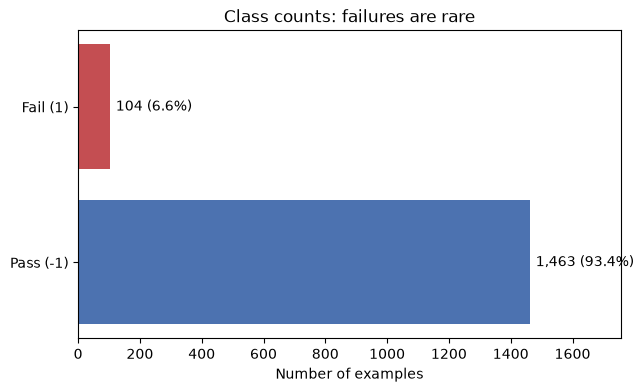

In [6]:
# Keep the original labels for display, and make a 0/1 target for later steps.
target = labels[0].map({-1: 0, 1: 1})

class_counts = labels[0].value_counts().sort_index()
class_percent = class_counts / len(labels) * 100

for label, count, pct in zip(class_counts.index, class_counts.values, class_percent.values):
    meaning = "pass" if label == -1 else "fail"
    print(f"{label:>2} ({meaning}): {count:4d} examples ({pct:.1f}%)")

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.barh(
    ["Pass (-1)", "Fail (1)"],
    class_counts.values,
    color=["#4C72B0", "#C44E52"],
)
ax.bar_label(
    bars,
    labels=[f"{c:,} ({p:.1f}%)" for c, p in zip(class_counts.values, class_percent.values)],
    padding=4,
)
ax.set_xlabel("Number of examples")
ax.set_title("Class counts: failures are rare")
ax.set_xlim(0, class_counts.max() * 1.2)
plt.show()

### What the chart shows

The dataset has 1,463 passes (93.4%) and 104 failures (6.6%). Because passes
dominate, a model that always predicts "pass" would be correct 93.4% of the time
while never finding a failure. That is why accuracy is not used as the main
measure in this project. Later evaluation will focus on how many failures are
found (recall), how many flagged cases are really failures (precision), and
metrics that account for both classes.

## Missing values

The next cells quantify how much data is missing, where it is concentrated, and
whether the pass and fail groups differ in how incomplete their rows are. The
0/1 `target` from the previous section is used for the class comparison.

In [7]:
missing_by_feature = features.isna().sum()
missing_by_row = features.isna().sum(axis=1)

print("Total missing values:", int(missing_by_feature.sum()))
print("Total cells:", features.size)
print(f"Missing share: {missing_by_feature.sum() / features.size:.2%}")
print()
print("Features with no missing values:", int((missing_by_feature == 0).sum()))
print("Features with >50% missing:", int((missing_by_feature / len(features) > 0.50).sum()))
print("Features with >90% missing:", int((missing_by_feature / len(features) > 0.90).sum()))
print()
print("Missing values per row:")
print(missing_by_row.describe().round(1).to_string())

missing_by_class = (
    pd.DataFrame({"missing_values": missing_by_row, "target": target})
    .groupby("target")["missing_values"]
    .agg(["count", "mean", "median", "max"])
    .rename(index={0: "Pass (0)", 1: "Fail (1)"})
)
missing_by_class.round(1)

Total missing values: 41951
Total cells: 924530
Missing share: 4.54%

Features with no missing values: 52
Features with >50% missing: 28
Features with >90% missing: 4

Missing values per row:
count    1567.0
mean       26.8
std        13.4
min         4.0
25%        20.0
50%        24.0
75%        32.0
max       152.0


,count,mean,median,max
target,,,,
Pass (0),1463,26.9,24.0,152
Fail (1),104,25.5,24.0,64


### What the missing-value summary shows

About 4.5% of all measurement values are missing (41,951 of 924,530 cells).
Missingness is concentrated in a subset of features: 52 features are complete,
28 are more than 50% missing, and 4 are more than 90% missing. No feature is
entirely missing, and no row is mostly empty: the median row has 24 missing
values, and the worst row has 152 (25.8% of its 590 values).

The pass and fail groups have very similar row-level missingness (median 24
values in both), so there is no obvious sign that missingness alone separates
the classes. This should still be checked inside validation folds.

### Which features are most incomplete?

A horizontal bar chart of the 15 most-missing features makes the small group of
sparsely measured sensors easy to see.

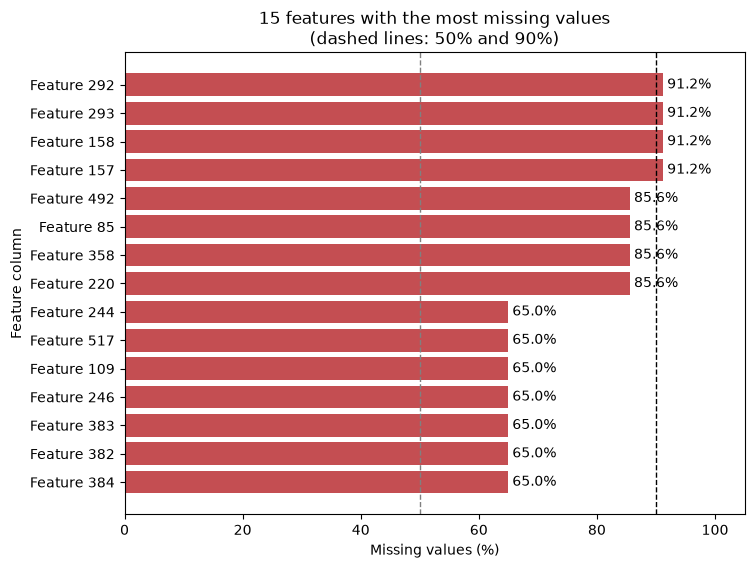

In [8]:
missing_pct = (missing_by_feature / len(features) * 100).sort_values(ascending=False)
top_missing = missing_pct.head(15)

fig, ax = plt.subplots(figsize=(8, 6))
bars = ax.barh(
    [f"Feature {c}" for c in top_missing.index][::-1],
    top_missing.values[::-1],
    color="#C44E52",
)
ax.bar_label(bars, fmt="%.1f%%", padding=3)
ax.axvline(50, color="gray", linestyle="--", linewidth=1)
ax.axvline(90, color="black", linestyle="--", linewidth=1)
ax.set_xlabel("Missing values (%)")
ax.set_ylabel("Feature column")
ax.set_title("15 features with the most missing values\n(dashed lines: 50% and 90%)")
ax.set_xlim(0, 105)
plt.show()

### What the most-missing features show

The four most incomplete features (columns 157, 158, 292, and 293) are missing
91.2% of the time. The next group (85, 220, 358, and 492) is missing 85.6%, and
several more — for example 109, 244, 246, 382, 383, 384, and 517 — are around
65% missing. These features carry very little information and would need careful
imputation if kept. The distribution below shows that most features are much
more complete than this small group.

### How is missingness spread across features and rows?

Two histograms show the same missing counts from different angles: one feature
at a time, and one row at a time.

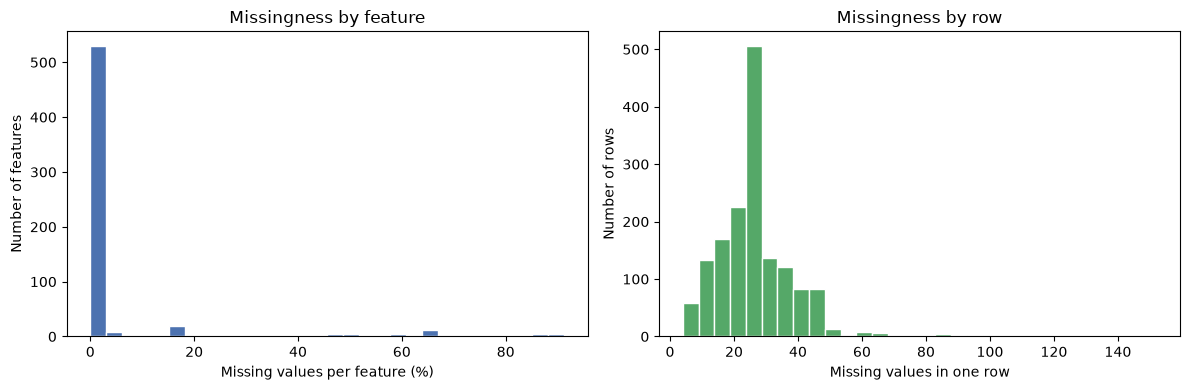

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(missing_pct, bins=30, color="#4C72B0", edgecolor="white")
axes[0].set_xlabel("Missing values per feature (%)")
axes[0].set_ylabel("Number of features")
axes[0].set_title("Missingness by feature")

axes[1].hist(missing_by_row, bins=30, color="#55A868", edgecolor="white")
axes[1].set_xlabel("Missing values in one row")
axes[1].set_ylabel("Number of rows")
axes[1].set_title("Missingness by row")

plt.tight_layout()
plt.show()

### What the histograms show

Most features are either complete or only slightly incomplete, with a long tail
of sparsely measured features. Row-level missingness is much more concentrated:
most rows are missing roughly 20–32 values, and the maximum is 152. This means
dropping rows would remove data unnecessarily; the main decision is how to
handle incomplete features.

## Constant and near-constant features

A feature that never changes cannot help a model. We count features with at
most one distinct non-missing value, and features where more than 99% of the
non-missing values are the same. The second group is "near-constant".

In [10]:
unique_counts = features.nunique(dropna=True)

dominant_share = {}
for col in features.columns:
    values = features[col].dropna()
    dominant_share[col] = values.value_counts(normalize=True).iloc[0] if len(values) else 1.0
dominant_share = pd.Series(dominant_share)

constant_features = unique_counts[unique_counts <= 1]
near_constant_features = unique_counts[(unique_counts > 1) & (dominant_share > 0.99)]
n_variable = len(features.columns) - len(constant_features) - len(near_constant_features)

only_zero_or_nan = ((features == 0) | features.isna()).all()

print("Constant features (one unique value):", len(constant_features))
print("Near-constant features (>99% one value):", len(near_constant_features))
print("Variable features:", n_variable)
print("Constant features that are only 0 or NaN:", int(only_zero_or_nan.sum()))

Constant features (one unique value): 116
Near-constant features (>99% one value): 6
Variable features: 468
Constant features that are only 0 or NaN: 112


### What the low-variance check shows

116 features are constant (they contain only one distinct non-missing value),
and 6 more are near-constant (more than 99% of their values are the same). That
leaves 468 features with meaningful variation. 112 of the constant features
contain only 0 or NaN.

Constant features cannot help a model and can be removed with a variance filter,
but that filter must be fitted inside the training pipeline so validation folds
are not affected.

### Visualising feature variability

The histogram shows how many distinct non-missing values each feature has. The
bar chart groups the features into the three categories used above.

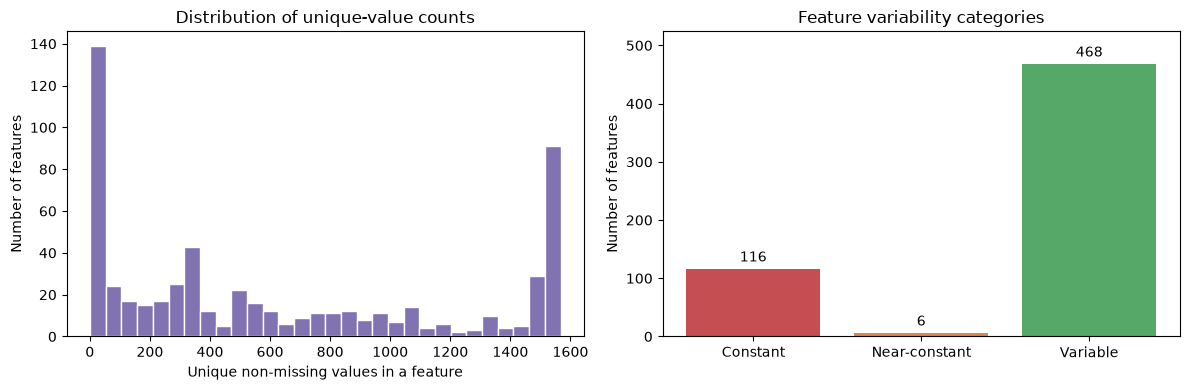

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(unique_counts, bins=30, color="#8172B2", edgecolor="white")
axes[0].set_xlabel("Unique non-missing values in a feature")
axes[0].set_ylabel("Number of features")
axes[0].set_title("Distribution of unique-value counts")

category_counts = pd.Series(
    {
        "Constant": len(constant_features),
        "Near-constant": len(near_constant_features),
        "Variable": n_variable,
    }
)
bars = axes[1].bar(
    category_counts.index,
    category_counts.values,
    color=["#C44E52", "#DD8452", "#55A868"],
)
axes[1].bar_label(bars, padding=3)
axes[1].set_ylim(0, category_counts.max() * 1.12)
axes[1].set_ylabel("Number of features")
axes[1].set_title("Feature variability categories")

plt.tight_layout()
plt.show()

### What the variability plots show

The histogram has a large spike at 1 unique value — the constant features — and
the rest spread across a wide range: the median feature has 450 distinct
non-missing values, and the maximum is 1,567. The category chart summarizes the
same information more directly: 116 constant, 6 near-constant, and 468 variable.

## Comparing pass and fail distributions

To keep the comparison readable, four features are selected with a simple
descriptive rule:

1. Keep features with less than 10% missing values, so the plots are not
   dominated by imputation.
2. For each remaining feature, compute the absolute standardized mean difference
   (Cohen's d): the difference between the fail and pass averages divided by the
   pooled standard deviation.
3. Plot the four features with the largest absolute values.

This is a **visualization aid only**. The ranking uses all rows, is not a
statistical test, and is not a validated feature-selection step. A visible gap
does not prove that a feature causes failure or that it will improve a model.
The same caution applies to every plot in this section.

In [12]:
usable_features = features.columns[features.isna().mean() < 0.10]

standardized_difference = {}
for col in usable_features:
    fail_values = features.loc[target == 1, col].dropna()
    pass_values = features.loc[target == 0, col].dropna()
    pooled_sd = ((fail_values.var() + pass_values.var()) / 2) ** 0.5
    if pooled_sd > 0:
        standardized_difference[col] = (fail_values.mean() - pass_values.mean()) / pooled_sd

standardized_difference = pd.Series(standardized_difference).abs().sort_values(ascending=False)
selected_features = standardized_difference.head(4).index.tolist()

selection_table = pd.DataFrame(
    {
        "feature": [f"Feature {c}" for c in selected_features],
        "abs_standardized_difference": standardized_difference.loc[selected_features].round(2).values,
        "pass_mean": [features.loc[target == 0, c].mean() for c in selected_features],
        "fail_mean": [features.loc[target == 1, c].mean() for c in selected_features],
        "missing_pct": [features[c].isna().mean() * 100 for c in selected_features],
    }
)
selection_table.round(2)

,feature,abs_standardized_difference,pass_mean,fail_mean,missing_pct
0,Feature 59,0.59,2.56,8.52,0.45
1,Feature 103,0.57,-0.01,-0.01,0.13
2,Feature 129,0.48,-0.59,-0.08,0.57
3,Feature 28,0.44,69.60,68.10,0.13


### Which features were selected?

The four features are 59, 103, 129, and 28, with absolute standardized
differences between 0.44 and 0.59. The table shows that feature 103 has a very
small standard deviation, so its standardized difference looks larger than its
absolute shift: its group averages differ by only about 0.002 measurement units.
Feature 59 has the clearest difference in medians (0.72 for passes vs 5.52 for
failures), but the distributions still overlap substantially.

### The boxplots

Each panel compares passes and failures for one selected feature. The box shows
the middle 50% of values, the line inside is the median, and the whiskers and
dots show the rest of the distribution.

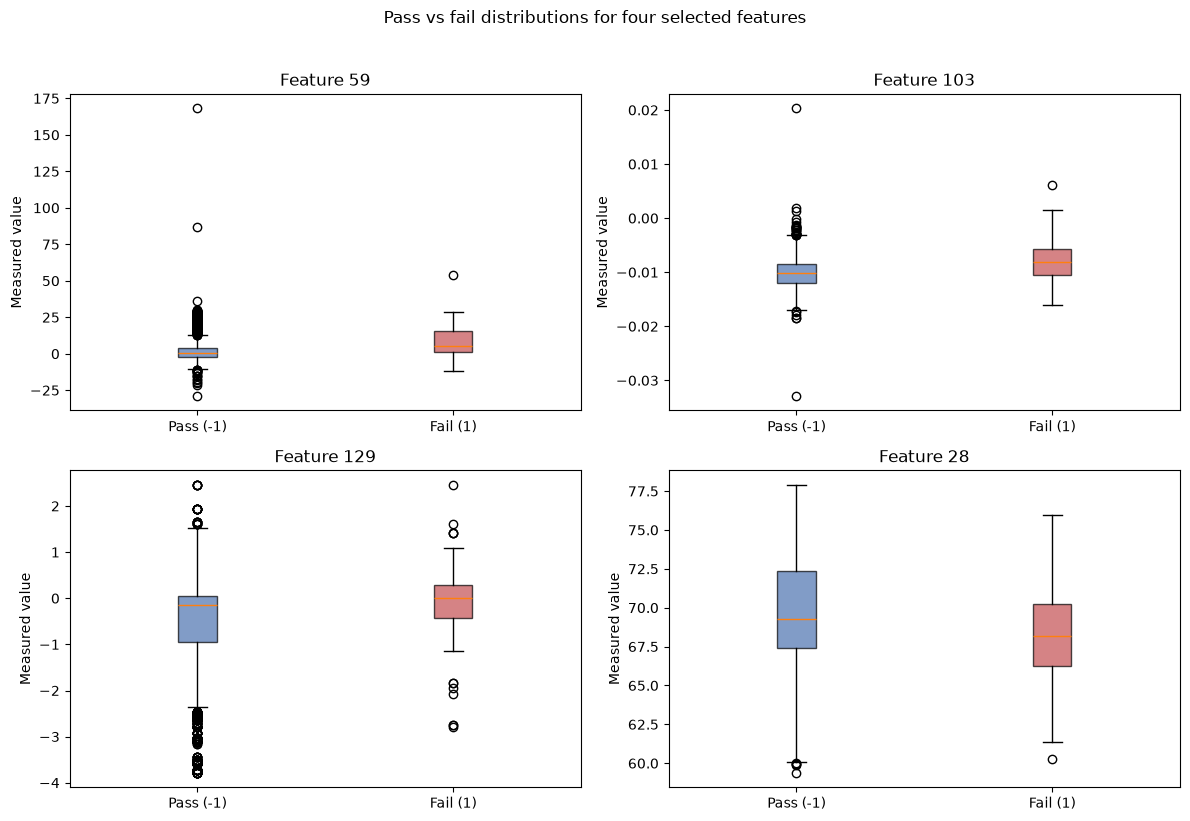

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, col in zip(axes.ravel(), selected_features):
    pass_values = features.loc[target == 0, col].dropna()
    fail_values = features.loc[target == 1, col].dropna()
    bp = ax.boxplot(
        [pass_values, fail_values],
        tick_labels=["Pass (-1)", "Fail (1)"],
        patch_artist=True,
    )
    for patch, color in zip(bp["boxes"], ["#4C72B0", "#C44E52"]):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)
    ax.set_title(f"Feature {col}")
    ax.set_ylabel("Measured value")

plt.suptitle("Pass vs fail distributions for four selected features", y=1.02)
plt.tight_layout()
plt.show()

### What the boxplots show

- **Feature 59:** failures tend to have higher values (median about 5.5 vs 0.7),
  but the pass group has a long upper tail and the groups overlap.
- **Feature 129:** failures are shifted toward zero and are more tightly
  clustered; passes are more spread out and lower on average.
- **Feature 28:** the medians differ by only about 1.1 units on a scale where
  values are typically around 69, and the boxes overlap heavily.
- **Feature 103:** the absolute values are tiny (around -0.01) and the boxes are
  shifted by only about 0.002 units, despite the larger standardized difference.

Across all four, the classes overlap. These plots do not establish that any
feature is predictive, and they do not show causation. They only suggest
patterns that model validation should examine more carefully.

## Relationships among the selected features

A small correlation matrix shows whether the four selected features carry
overlapping information. A 4 × 4 grid is readable; a plot of all 590 features
would not be.

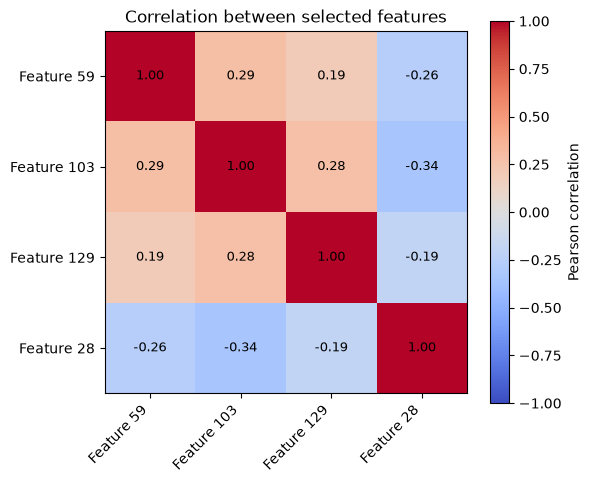

In [14]:
selected_corr = features[selected_features].corr()

fig, ax = plt.subplots(figsize=(6, 5))
image = ax.imshow(selected_corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(selected_features)))
ax.set_yticks(range(len(selected_features)))
ax.set_xticklabels([f"Feature {c}" for c in selected_features], rotation=45, ha="right")
ax.set_yticklabels([f"Feature {c}" for c in selected_features])
for i in range(len(selected_features)):
    for j in range(len(selected_features)):
        ax.text(
            j,
            i,
            f"{selected_corr.iloc[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=9,
        )
ax.set_title("Correlation between selected features")
fig.colorbar(image, ax=ax, label="Pearson correlation")
plt.tight_layout()
plt.show()

### What the correlation matrix shows

The correlations are weak to moderate: the strongest is about -0.34 (features 28
and 103), and the rest are between -0.26 and 0.29. No pair is close to redundant,
so the four plots are showing four different patterns rather than four copies of
the same signal. This describes only these four features; it says nothing about
the remaining 586 columns.

## What to check during model validation

- **Only 104 failures.** A 20% test set would contain roughly 21 failures, so a
  single split can give unstable estimates. Use stratified splits or
  cross-validation, and report precision, recall, balanced accuracy, ROC-AUC,
  and PR-AUC / average precision. Do not use accuracy as the main measure.
- **Missing data.** About 4.5% of values are missing, with 28 features above 50%
  missing and 4 above 90%. Fit imputation inside each training fold and compare
  simple median imputation with alternatives. Consider missing-indicators for
  features where missingness may carry information, and check whether
  missingness differs between the classes in validation.
- **Low-variance features.** 116 constant and 6 near-constant features carry
  almost no information. Use a variance filter inside the pipeline; do not drop
  columns based on the full dataset before splitting.
- **Selected-feature differences are descriptive.** The four features above were
  chosen to make plots readable, using all rows. They must not be hard-coded as
  a feature-selection result. Model validation should decide whether any feature
  or group of features is useful.
- **Correlations are modest.** The selected features are not strongly redundant,
  but other feature pairs may be. Regularized linear models can handle
  correlated inputs; tree models may split importance between them.
- **Time order.** The rows are in chronological order. A time-based validation
  check is worth considering, because process conditions can change over time.
- **No model has been trained in this notebook.**

## Preparing data for modeling

### Stratified train/test split

Before any preprocessing or modeling, the data is divided into a training
portion and a test set. The test set is held back and used once, at the very
end, to estimate how the final model performs on examples it has not seen.

**What stratification does:** `train_test_split` normally draws a random sample.
With a rare class, a plain random split could put too few failures in one of the
sets by chance. `stratify=y` keeps the pass/fail proportions in both sets, so the
splits have roughly the same failure rate as the full dataset.

**Why the test set stays untouched:** every choice made later — imputation,
scaling, feature selection, hyperparameters, and the decision threshold — must
be based only on data that excludes the test set. If the test set were used to
make those choices, the final score would be optimistic and would not represent
performance on new examples.

The training portion is split again into a training set and a validation set in
the next step. No preprocessing is fitted here, no features are selected, no
resampling is done, and no model is trained.

In [15]:
from sklearn.model_selection import train_test_split

# Fail (1) is the positive class; pass (-1) becomes 0.
X = features
y = labels[0].map({-1: 0, 1: 1})

# Hold out 20% of all examples as the final test set.
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42,
)

print("Training portion:", X_train_full.shape)
print("Test set:        ", X_test.shape)
print(f"Training-portion failure rate: {y_train_full.mean():.2%}")
print(f"Test failure rate:             {y_test.mean():.2%}")
print("Overlapping row indices:", len(set(X_train_full.index) & set(X_test.index)))

Training portion: (1253, 590)
Test set:         (314, 590)
Training-portion failure rate: 6.62%
Test failure rate:             6.69%
Overlapping row indices: 0


### Validation split

The validation set is carved out of the training portion, not the test set. It
is 20% of the training portion and is used for model comparison, hyperparameter
tuning, and choosing the decision threshold. The test set is not used for any of
these decisions.

Stratification is applied again so the small failure class stays represented in
both the final training set and the validation set. The split uses the same
fixed seed for reproducibility.

In [16]:
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.20,
    stratify=y_train_full,
    random_state=42,
)

print("X_train:", X_train.shape)
print("X_val:  ", X_val.shape)
print("X_test: ", X_test.shape)
print()
print(f"Train failure rate:      {y_train.mean():.2%}")
print(f"Validation failure rate: {y_val.mean():.2%}")
print(f"Test failure rate:       {y_test.mean():.2%}")
print()
print("Train/validation overlap:", len(set(X_train.index) & set(X_val.index)))
print("Train/test overlap:      ", len(set(X_train.index) & set(X_test.index)))
print("Validation/test overlap: ", len(set(X_val.index) & set(X_test.index)))

X_train: (1002, 590)
X_val:   (251, 590)
X_test:  (314, 590)

Train failure rate:      6.59%
Validation failure rate: 6.77%
Test failure rate:       6.69%

Train/validation overlap: 0
Train/test overlap:       0
Validation/test overlap:  0


In [17]:
split_table = pd.DataFrame(
    {
        "split": ["Train", "Validation", "Test"],
        "examples": [len(y_train), len(y_val), len(y_test)],
        "pass (0)": [
            int((y_train == 0).sum()),
            int((y_val == 0).sum()),
            int((y_test == 0).sum()),
        ],
        "fail (1)": [
            int((y_train == 1).sum()),
            int((y_val == 1).sum()),
            int((y_test == 1).sum()),
        ],
        "fail percent": [
            y_train.mean() * 100,
            y_val.mean() * 100,
            y_test.mean() * 100,
        ],
    }
)
split_table["fail percent"] = split_table["fail percent"].round(2)
split_table

,split,examples,pass (0),fail (1),fail percent
0,Train,1002,936,66,6.59
1,Validation,251,234,17,6.77
2,Test,314,293,21,6.69


### What the three-way split shows

- **Training:** 1,002 examples, including 66 failures (6.59%).
- **Validation:** 251 examples, including 17 failures (6.77%).
- **Test:** 314 examples, including 21 failures (6.69%).

All three splits are close to the full-dataset failure rate of 6.64%, so
stratification worked. The row indices do not overlap: each example appears in
exactly one split.

Use the validation set for model comparison, hyperparameter tuning, and
threshold selection. Keep the test set untouched until the final evaluation.
Because the test set contains only 21 failures, the final metrics will still be
uncertain, so report them with that limitation in mind. If hyperparameters and
the threshold are chosen on validation data, a common final step is to refit the
selected model on the training plus validation data and then evaluate once on
the test set. That refit is what the saved artifact is: the artifact cell at the
end of this notebook fits the selected configuration on all 1,253 rows of
`X_train` plus `X_val`, and the final holdout section scores `X_test` with that
artifact exactly once.

### Preprocessing pipeline

The models used later expect numeric input with no missing values and with
features on comparable scales. Those two preparations are learned from data, so
they must be learned from the **training set only** and then applied to the
validation set.

A scikit-learn `Pipeline` bundles the steps so they always run in the same order
and are fitted as one object. The steps are:

1. **`SimpleImputer(strategy="median")`** — fills each `NaN` with that column's
   median.
2. **`VarianceThreshold(threshold=0.0)`** — drops columns that have no variation
   at all after imputation.
3. **`StandardScaler()`** — centers each remaining column at 0 and scales it to
   unit variance.

The order matters. Imputation comes first because the scaler cannot handle
`NaN`. The variance filter sits between them because a column can become
constant once its missing values are filled in. Scaling comes last so that only
columns that survive are scaled.

`fit_transform` is called on `X_train` only: this is where the medians, the
kept-column mask, and the means and standard deviations are learned. `X_val` is
only `transform`ed, which applies the training statistics without recomputing
them. `X_test` is not touched in this step.

In [18]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.preprocessing import StandardScaler

preprocess = Pipeline(
    [
        ("impute_median", SimpleImputer(strategy="median")),
        ("remove_constant", VarianceThreshold(threshold=0.0)),
        ("scale", StandardScaler()),
    ]
)

# Fit on the training set only, then apply to training and validation.
X_train_prepared = preprocess.fit_transform(X_train)
X_val_prepared = preprocess.transform(X_val)

print("X_train shape before:", X_train.shape)
print("X_train shape after: ", X_train_prepared.shape)
print("X_val shape before:  ", X_val.shape)
print("X_val shape after:   ", X_val_prepared.shape)
print()
print("Missing values in X_train_prepared:", int(pd.isna(X_train_prepared).sum()))
print("Missing values in X_val_prepared:  ", int(pd.isna(X_val_prepared).sum()))

X_train shape before: (1002, 590)
X_train shape after:  (1002, 468)
X_val shape before:   (251, 590)
X_val shape after:    (251, 468)

Missing values in X_train_prepared: 0
Missing values in X_val_prepared:   0


### What each step learned from the training data

The fitted pipeline stores what each step learned. Reading those attributes
makes the learning concrete:

- `imputer.statistics_` holds one median per original column (590 values).
- `variance_filter.get_support()` is a True/False mask over columns, marking
  which ones were kept.
- `scaler.mean_` and `scaler.scale_` hold the mean and standard deviation of
  each surviving column.

In [19]:
imputer = preprocess.named_steps["impute_median"]
variance_filter = preprocess.named_steps["remove_constant"]
scaler = preprocess.named_steps["scale"]

n_original = imputer.statistics_.shape[0]
kept_mask = variance_filter.get_support()
n_removed = int((~kept_mask).sum())

print(f"Medians learned by the imputer: {n_original}")
print(f"Columns removed by the variance filter: {n_removed}")
print(f"Columns kept for scaling: {int(kept_mask.sum())}")
print(f"Means learned by the scaler: {scaler.mean_.shape[0]}")
print(f"Scales (standard deviations) learned by the scaler: {scaler.scale_.shape[0]}")
print()
print(f"Mean of scaled training values:  {X_train_prepared.mean():.2e}")
print(f"Std of scaled training values:   {X_train_prepared.std():.2e}")

Medians learned by the imputer: 590
Columns removed by the variance filter: 122
Columns kept for scaling: 468
Means learned by the scaler: 468
Scales (standard deviations) learned by the scaler: 468

Mean of scaled training values:  8.18e-17
Std of scaled training values:   1.00e+00


### What the result shows

- **Shapes:** `X_train` went from `(1002, 590)` to `(1002, 468)`, and `X_val`
  from `(251, 590)` to `(251, 468)`. No rows were dropped; only columns were
  removed.
- **Missing values:** both prepared arrays contain 0 missing values. Every `NaN`
  was replaced by its training median.
- **Imputation:** the imputer learned 590 medians, one for every original
  column. Some columns had no missing values in the training set, in which case
  the median is simply the column's typical value.
- **Variance filter:** 122 columns were removed and 468 kept. The EDA counted
  116 constant columns across the whole dataset, and this step removes slightly
  more because it looks only at the 1,002 training rows. A few features that
  vary somewhere in the full dataset happen to have a single value inside the
  training rows, so from the pipeline's point of view they carry no information
  and are dropped. That is the correct behaviour: the decision is based on
  training data only.
- **Scaling:** the scaler learned 468 means and 468 standard deviations, one per
  kept column. After scaling, the training values have a mean of about 0 and a
  standard deviation of about 1, so features measured in very different units
  (some near -0.01, others in the hundreds) now contribute comparably to a
  regularized logistic regression.

Two cautions for later steps:

- `X_val_prepared` uses the **training** medians, means, and scales. It is not
  refitted, which is what keeps the validation estimate honest.
- `X_test` has not been transformed. It stays untouched until the final
  evaluation, and then it must go through this same `preprocess` object.

## First model comparison

This section answers a narrow question: with the preprocessing already defined
and the **default 0.5 decision threshold**, how do five quite different models
behave on the validation set?

Each model is a single scikit-learn `Pipeline`. Putting preprocessing and the
classifier in one object means every `fit` call reruns imputation, the constant
filter, and (where used) scaling on the training rows only. There is no chance
of fitting a transformer on validation data by accident.

The five candidates cover a spread of model families:

- **`DummyClassifier(strategy="most_frequent")`** — always predicts the majority
  class. It is the no-skill reference the real models must beat.
- **`LogisticRegression(class_weight="balanced")`** — a linear model. The
  scaling step matters here, because regularized logistic regression is sensitive
  to features on different scales.
- **`RandomForestClassifier(class_weight="balanced")`** — a bagged ensemble of
  trees. Tree models are invariant to monotonic rescaling, so the scaler is
  omitted.
- **`DecisionTreeClassifier(class_weight="balanced")`** — a single tree. It can
  express sharp non-linear rules, but a single unpruned tree readily memorizes
  the training rows. No scaling is needed.
- **`HistGradientBoostingClassifier(class_weight="balanced")`** — boosted trees
  fitted stage by stage, each stage correcting the previous one. Also
  scale-invariant. It can handle missing values natively, but median imputation
  is still applied so that every model receives exactly the same input and the
  comparison stays fair.

`class_weight="balanced"` tells the four real models to weight the rare failure
class more heavily, which partially offsets the 93%/7% imbalance without
resampling or fabricating examples.

**Failure (label `1`) is the positive class** in every metric below. Precision
answers "of the examples flagged as failures, how many really failed?" Recall
answers "of the real failures, how many were flagged?" Balanced accuracy is the
average of the two per-class recalls, so it cannot be inflated by the large
number of easy passes. Average precision (the area under the precision-recall
curve) is the most informative single ranking number for a class this rare.

The confusion counts reported for each model are read as:

| | Predicted pass | Predicted fail |
|---|---|---|
| **Actually passed** | true pass (TN) | false alarm (FP) |
| **Actually failed** | missed failure (FN) | caught failure (TP) |

This is a **first comparison, not a final answer**. Every model is judged at the
single default cut of 0.5, hyperparameters are untuned, and the test set is not
used. `X_test` and `y_test` stay untouched until the final evaluation.


In [20]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import HistGradientBoostingClassifier

# Shared preprocessing: the steps that every model needs.
shared_steps = [
    ("impute_median", SimpleImputer(strategy="median")),
    ("remove_constant", VarianceThreshold(threshold=0.0)),
]

candidates = {
    "Dummy (most frequent)": Pipeline(
        shared_steps + [("classifier", DummyClassifier(strategy="most_frequent"))]
    ),
    "Logistic regression": Pipeline(
        shared_steps
        + [
            ("scale", StandardScaler()),
            # max_iter is a convergence safeguard, not a tuned setting.
            ("classifier", LogisticRegression(
                class_weight="balanced", max_iter=2000, random_state=42
            )),
        ]
    ),
    "Random forest": Pipeline(
        shared_steps
        + [
            ("classifier", RandomForestClassifier(
                class_weight="balanced", random_state=42
            )),
        ]
    ),
    "Decision tree": Pipeline(
        shared_steps
        + [
            ("classifier", DecisionTreeClassifier(
                class_weight="balanced", random_state=42
            )),
        ]
    ),
    "Hist gradient boosting": Pipeline(
        shared_steps
        + [
            ("classifier", HistGradientBoostingClassifier(
                class_weight="balanced", random_state=42
            )),
        ]
    ),
}

print("Candidates:", len(candidates))
for name, pipe in candidates.items():
    print(f"  {name}: {[step for step, _ in pipe.steps]}")


Candidates: 5
  Dummy (most frequent): ['impute_median', 'remove_constant', 'classifier']
  Logistic regression: ['impute_median', 'remove_constant', 'scale', 'classifier']
  Random forest: ['impute_median', 'remove_constant', 'classifier']
  Decision tree: ['impute_median', 'remove_constant', 'classifier']
  Hist gradient boosting: ['impute_median', 'remove_constant', 'classifier']


In [21]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    roc_auc_score,
    average_precision_score,
)

rows = []
for name, pipeline in candidates.items():
    pipeline.fit(X_train, y_train)

    # Hard labels at the default 0.5 threshold.
    val_predictions = pipeline.predict(X_val)
    # Probability of the positive class (failure), used for ranking metrics.
    val_probabilities = pipeline.predict_proba(X_val)[:, 1]

    # Confusion counts. Failure is the positive class.
    caught = int(((val_predictions == 1) & (y_val == 1)).sum())   # TP
    missed = int(((val_predictions == 0) & (y_val == 1)).sum())   # FN
    false_alarms = int(((val_predictions == 1) & (y_val == 0)).sum())  # FP
    true_passes = int(((val_predictions == 0) & (y_val == 0)).sum())   # TN

    rows.append(
        {
            "model": name,
            "true_pass_TN": true_passes,
            "false_alarm_FP": false_alarms,
            "missed_FN": missed,
            "caught_TP": caught,
            "precision": precision_score(y_val, val_predictions, pos_label=1, zero_division=0),
            "recall": recall_score(y_val, val_predictions, pos_label=1, zero_division=0),
            "f1": f1_score(y_val, val_predictions, pos_label=1, zero_division=0),
            "balanced_accuracy": balanced_accuracy_score(y_val, val_predictions),
            "roc_auc": roc_auc_score(y_val, val_probabilities),
            "average_precision": average_precision_score(y_val, val_probabilities),
        }
    )

comparison = pd.DataFrame(rows).set_index("model").round(3)
comparison


,true_pass_TN,false_alarm_FP,missed_FN,caught_TP,precision,recall,f1,balanced_accuracy,roc_auc,average_precision
model,,,,,,,,,,
Dummy (most frequent),234,0,17,0,0.000,0.000,0.000,0.500,0.500,0.068
Logistic regression,204,30,12,5,0.143,0.294,0.192,0.583,0.661,0.220
Random forest,234,0,17,0,0.000,0.000,0.000,0.500,0.746,0.158
Decision tree,222,12,15,2,0.143,0.118,0.129,0.533,0.533,0.077
Hist gradient boosting,232,2,17,0,0.000,0.000,0.000,0.496,0.665,0.155


In [22]:
print(f"Validation examples: {len(y_val)}")
print(f"Validation failures (positive class): {int(y_val.sum())}")
print(f"Validation failure rate: {y_val.mean():.2%}")
print(f"Default decision threshold: 0.5")

Validation examples: 251
Validation failures (positive class): 17
Validation failure rate: 6.77%
Default decision threshold: 0.5


### What the comparison shows

The validation set has 251 examples, of which 17 are failures (6.77%). All five
models are scored at the default 0.5 cut, so these are unoptimized numbers.

| Model | Caught (TP) | Missed (FN) | False alarms (FP) | True pass (TN) | Precision | Recall | F1 | Balanced acc. | ROC-AUC | Avg. prec. |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| Dummy (most frequent) | 0 | 17 | 0 | 234 | 0.000 | 0.000 | 0.000 | 0.500 | 0.500 | 0.068 |
| Logistic regression | 5 | 12 | 30 | 204 | 0.143 | 0.294 | 0.192 | 0.583 | 0.661 | 0.220 |
| Random forest | 0 | 17 | 0 | 234 | 0.000 | 0.000 | 0.000 | 0.500 | 0.746 | 0.158 |
| Decision tree | 2 | 15 | 12 | 222 | 0.143 | 0.118 | 0.129 | 0.533 | 0.533 | 0.077 |
| Hist gradient boosting | 0 | 17 | 2 | 232 | 0.000 | 0.000 | 0.000 | 0.496 | 0.665 | 0.155 |

Every row sums to the 251 validation examples: for example, logistic regression
gives 5 + 12 + 30 + 204 = 251, and 5 + 12 = 17 failures.

**The dummy sets the floor.** It flags nothing, so it catches 0 of 17 failures
and its precision, recall, and F1 are all 0. Balanced accuracy is exactly 0.500,
the value a model gets when one class is never predicted. Its ROC-AUC of 0.500
is exact — a constant score contains no ranking information — and its average
precision of 0.068 is simply the failure rate, the level a real ranking model
must beat. Its accuracy would look like about 93.2%, which is precisely why
accuracy is not the measure used here.

**Logistic regression is still the only model that catches anything useful at
0.5.** It catches 5 of 17 failures while raising 30 false alarms. That is a
recall of 0.294 and a precision of 0.143, the highest F1 (0.192), the highest
balanced accuracy (0.583) and the highest average precision (0.220). It is also
the model whose probability scale actually spans the full range, so a 0.5 cut
means something.

**The random forest catches nothing at 0.5** yet has the best ROC-AUC (0.746).
That combination is not a contradiction: the forest ranks examples reasonably
well but never gives any validation example a failure probability above 0.48, so
the 0.5 cut flags nobody. Its ranking ability is real; its operating point is
simply misplaced.

**The decision tree is the weakest real model here.** It catches 2 of 17 with
12 false alarms, and its ROC-AUC (0.533) is barely above a coin flip, with
average precision (0.077) almost at the no-skill level of 0.068. This is the
classic behaviour of a single unpruned tree on 1,002 rows with 590 columns: it
grows a deep tree (depth 35, 52 leaves) that separates the training rows almost
perfectly, and its leaf proportions then generalize poorly. That is a sign that
`max_depth`, `min_samples_leaf`, and pruning options will matter a lot here —
not evidence that decision trees are useless.

**Hist gradient boosting catches nothing at 0.5 either**, though it flags 2
examples (both false alarms). Its balanced accuracy of 0.496 is fractionally
below 0.5 for that reason: it catches no failures and gets only 2 of 234 passes
wrong. But its ranking metrics are respectable — ROC-AUC 0.665 and average
precision 0.155 — so like the forest it is being judged at a cut that does not
suit its probability scale, which tops out at about 0.70.

### How to read this without picking a winner

The models disagree about what "good" means, and the metrics disagree too:

- **Logistic regression** leads on average precision, F1, and balanced accuracy.
- **Random forest** leads on ROC-AUC but has no usable operating point at 0.5.
- **Hist gradient boosting** sits in the middle on ranking and also has no
  usable operating point at 0.5.
- **Decision tree** is last on average precision, which is the metric closest to
  what this project cares about.

With only 17 validation failures, one example moving between cells changes
recall by almost 6 points, so these gaps are not precise. The fair summary is
that **logistic regression is the only candidate currently producing usable
flags, and even it is far from good** — roughly six in seven of its flags are
false alarms.

Three things are deliberately left undone, and all of them could change this
picture:

1. **Threshold tuning.** The tree-based models are being scored at a cut their
   probabilities rarely reach. The next section sweeps thresholds for all four real
   candidates.
2. **Hyperparameter tuning.** The forest, single tree, and gradient-boosting
   defaults are all untuned, and the single tree is clearly overfitting.
3. **Final evaluation.** `X_test` and `y_test` are still untouched.


In [23]:
# Why does a 0.5 cut behave so differently across these models?
# The spread of predicted probabilities answers that directly.
score_rows = []
for name, pipeline in candidates.items():
    probabilities = pipeline.predict_proba(X_val)[:, 1]
    score_rows.append(
        {
            "model": name,
            "min_prob": probabilities.min(),
            "median_prob": float(pd.Series(probabilities).median()),
            "max_prob": probabilities.max(),
            "flagged_at_0.5": int((probabilities >= 0.5).sum()),
        }
    )

score_summary = pd.DataFrame(score_rows).set_index("model").round(3)
print(score_summary.to_string())
print()

# The single tree's size shows how far it went in fitting the training rows.
tree = candidates["Decision tree"].named_steps["classifier"]
print(f"Decision tree: depth={tree.get_depth()}, leaves={tree.get_n_leaves()}")
print(f"Hist gradient boosting: boosting stages actually run={candidates['Hist gradient boosting'].named_steps['classifier'].n_iter_}")


                        min_prob  median_prob  max_prob  flagged_at_0.5
model                                                                  
Dummy (most frequent)       0.00        0.000     0.000               0
Logistic regression         0.00        0.000     1.000              35
Random forest               0.03        0.130     0.480               0
Decision tree               0.00        0.000     1.000              14
Hist gradient boosting      0.00        0.001     0.702               2

Decision tree: depth=35, leaves=52
Hist gradient boosting: boosting stages actually run=100


## Threshold tradeoff: catching failures vs false alarms

A classifier that outputs probabilities does not by itself decide who is flagged.
That decision comes from a threshold: an example is flagged as a failure when its
predicted failure probability is at or above the cut. The default 0.5 is only a
convention, and for a target where failures are about 7% of the data it is a
poorly placed convention — the previous section showed two models crossing it for
no example at all.

This section sweeps the same small, fixed set of thresholds — **0.10, 0.20, 0.30,
0.40, and 0.50** — for **all four real candidates**, and reports what each cut
would do on the validation set. The dummy classifier is left out: its score is
constant, so every cut produces the same "flag nobody" result.

The two errors are counted separately, because they cost different things:

- A **missed failure** (false negative): a failing lot passes review. Fewer of
  these is better, and only recall measures this.
- A **false alarm** (false positive): a passing lot is sent to review
  unnecessarily. More of these makes the flag less trustworthy and more
  expensive to operate, and precision measures this.

Lowering the threshold usually catches more failures *and* raises more false
alarms. There is no free lunch; the sweep just makes the exchange rate visible.
Where a model has no resolution in this range, the exchange rate can be flat
rather than smooth, and that is itself informative.

All four pipelines were fitted on `X_train` in the previous section, so they are
reused here without refitting. Probabilities come from `predict_proba` on
`X_val` only. `X_test` and `y_test` are not used.


In [24]:
from sklearn.utils.validation import check_is_fitted

real_candidates = [
    "Logistic regression",
    "Random forest",
    "Decision tree",
    "Hist gradient boosting",
]

# One colour per model, reused by both plots below so they stay consistent.
MODEL_COLORS = {
    "Logistic regression": "#4C72B0",
    "Random forest": "#C44E52",
    "Decision tree": "#55A868",
    "Hist gradient boosting": "#8172B2",
}

# Reuse the pipelines fitted on X_train in the comparison section above.
val_probability = {}
for name in real_candidates:
    check_is_fitted(candidates[name])
    val_probability[name] = candidates[name].predict_proba(X_val)[:, 1]

print(f"Validation examples: {len(y_val)}")
print(f"Validation failures: {int(y_val.sum())}")
print()
for name, proba in val_probability.items():
    print(
        f"{name}: min={proba.min():.4f}  median={pd.Series(proba).median():.4f}  "
        f"max={proba.max():.4f}"
    )


Validation examples: 251
Validation failures: 17

Logistic regression: min=0.0000  median=0.0003  max=1.0000
Random forest: min=0.0300  median=0.1300  max=0.4800
Decision tree: min=0.0000  median=0.0000  max=1.0000
Hist gradient boosting: min=0.0000  median=0.0011  max=0.7021


In [25]:
thresholds = [0.10, 0.20, 0.30, 0.40, 0.50]
n_failures = int(y_val.sum())
n_val = len(y_val)

rows = []
for name in real_candidates:
    probabilities = val_probability[name]
    for threshold in thresholds:
        flagged = probabilities >= threshold

        caught = int((flagged & (y_val == 1)).sum())
        missed = int((~flagged & (y_val == 1)).sum())
        false_alarms = int((flagged & (y_val == 0)).sum())
        n_flagged = int(flagged.sum())

        recall = caught / n_failures if n_failures else 0.0
        precision = caught / n_flagged if n_flagged else 0.0

        rows.append(
            {
                "model": name,
                "threshold": threshold,
                "caught": caught,
                "missed": missed,
                "false_alarms": false_alarms,
                "recall": recall,
                "precision": precision,
                "flagged": n_flagged,
                "flagged_pct": n_flagged / n_val * 100,
            }
        )

threshold_table = pd.DataFrame(rows)
threshold_table["recall"] = threshold_table["recall"].round(3)
threshold_table["precision"] = threshold_table["precision"].round(3)
threshold_table["flagged_pct"] = threshold_table["flagged_pct"].round(1)

threshold_table.set_index(["model", "threshold"])

caught  missed  false_alarms  recall  \
model                  threshold                                         
Logistic regression    0.1             6      11            50   0.353   
                       0.2             5      12            44   0.294   
                       0.3             5      12            39   0.294   
                       0.4             5      12            33   0.294   
                       0.5             5      12            30   0.294   
Random forest          0.1            17       0           163   1.000   
                       0.2             6      11            48   0.353   
                       0.3             2      15             8   0.118   
                       0.4             1      16             2   0.059   
                       0.5             0      17             0   0.000   
Decision tree          0.1             2      15            12   0.118   
                       0.2             2      15            12   0.118   
                       0.3             2      15            12   0.118   
                       0.4             2      15            12   0.118   
                       0.5             2      15            12   0.118   
Hist gradient boosting 0.1             2      15             3   0.118   
                       0.2             2      15             2   0.118   
                       0.3             2      15             2   0.118   
                       0.4             1      16             2   0.059   
                       0.5             0      17             2   0.000   

                                  precision  flagged  flagged_pct  
model                  threshold                                   
Logistic regression    0.1            0.107       56         22.3  
                       0.2            0.102       49         19.5  
                       0.3            0.114       44         17.5  
                       0.4            0.132       38         15.1  
                       0.5            0.143       35         13.9  
Random forest          0.1            0.094      180         71.7  
                       0.2            0.111       54         21.5  
                       0.3            0.200       10          4.0  
                       0.4            0.333        3          1.2  
                       0.5            0.000        0          0.0  
Decision tree          0.1            0.143       14          5.6  
                       0.2            0.143       14          5.6  
                       0.3            0.143       14          5.6  
                       0.4            0.143       14          5.6  
                       0.5            0.143       14          5.6  
Hist gradient boosting 0.1            0.400        5          2.0  
                       0.2            0.500        4          1.6  
                       0.3            0.500        4          1.6  
                       0.4            0.333        3          1.2  
                       0.5            0.000        2          0.8

In [26]:
# Check the table's arithmetic against the raw counts.
# Every row must satisfy: caught + missed == all failures,
# flagged == caught + false alarms, and recall / precision as defined.
n_val = len(y_val)
n_failures = int(y_val.sum())

checks = []
for name in real_candidates:
    probabilities = val_probability[name]
    for _, row in threshold_table[threshold_table["model"] == name].iterrows():
        flagged = probabilities >= row["threshold"]

        caught = int((flagged & (y_val == 1)).sum())
        missed = int((~flagged & (y_val == 1)).sum())
        false_alarms = int((flagged & (y_val == 0)).sum())
        true_passes = int((~flagged & (y_val == 0)).sum())
        n_flagged = int(flagged.sum())

        expected_recall = caught / n_failures
        expected_precision = caught / n_flagged if n_flagged else 0.0

        checks.append(
            {
                "model": name,
                "threshold": row["threshold"],
                "caught+missed==failures": caught + missed == n_failures,
                "flagged==caught+FP": n_flagged == caught + false_alarms,
                "confusion_sums_to_rows": caught + missed + false_alarms + true_passes == n_val,
                "counts_match_table": (
                    caught == row["caught"]
                    and missed == row["missed"]
                    and false_alarms == row["false_alarms"]
                    and n_flagged == row["flagged"]
                ),
                # The table is rounded to 3 decimals, so allow half a unit there.
                "recall_matches_counts": abs(row["recall"] - expected_recall) <= 0.0005,
                "precision_matches_counts": abs(row["precision"] - expected_precision) <= 0.0005,
            }
        )

audit = pd.DataFrame(checks)
check_columns = [c for c in audit.columns if c not in ("model", "threshold")]

print("Rows checked:", len(audit))
print("Failures of any check:", int((~audit[check_columns]).sum().sum()))
print("All checks passed:", bool(audit[check_columns].all().all()))
audit


Rows checked:

 20
Failures of any check: 0
All checks passed: True


,model,threshold,caught+missed==failures,flagged==caught+FP,confusion_sums_to_rows,counts_match_table,recall_matches_counts,precision_matches_counts
0,Logistic regression,0.1,True,True,True,True,True,True
1,Logistic regression,0.2,True,True,True,True,True,True
2,Logistic regression,0.3,True,True,True,True,True,True
3,Logistic regression,0.4,True,True,True,True,True,True
4,Logistic regression,0.5,True,True,True,True,True,True
5,Random forest,0.1,True,True,True,True,True,True
6,Random forest,0.2,True,True,True,True,True,True
7,Random forest,0.3,True,True,True,True,True,True
8,Random forest,0.4,True,True,True,True,True,True
9,Random forest,0.5,True,True,True,True,True,True


### Checking the table's arithmetic

Before trusting these numbers, the counts are recomputed from the stored
probabilities and compared with the printed table. Each row is tested for four
things:

1. `caught + missed` equals the total number of validation failures (17).
2. `flagged` equals `caught + false alarms`.
3. The four confusion cells together account for all 251 validation examples.
4. `recall` and `precision` equal the values implied by the counts
   (`caught / failures` and `caught / flagged`).

All rows pass. The columns and the calculations are consistent, so no correction
is required. The tolerance of 0.0005 in the last two checks exists only because
the table rounds its ratios to three decimals.

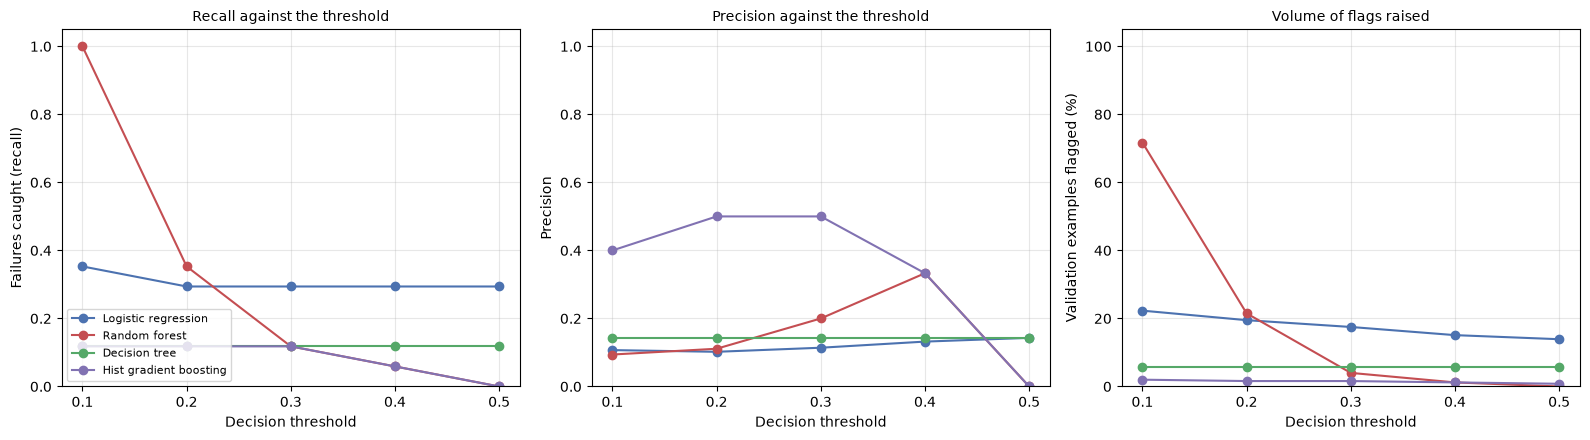

In [27]:
import matplotlib.pyplot as plt

panels = [
    ("recall", "Failures caught (recall)", "Recall against the threshold"),
    ("precision", "Precision", "Precision against the threshold"),
    ("flagged_pct", "Validation examples flagged (%)", "Volume of flags raised"),
]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, (column, ylabel, title) in zip(axes, panels):
    for name in real_candidates:
        subset = threshold_table[threshold_table["model"] == name]
        ax.plot(
            subset["threshold"],
            subset[column],
            marker="o",
            color=MODEL_COLORS[name],
            label=name,
        )
    ax.set_xlabel("Decision threshold")
    ax.set_ylabel(ylabel)
    ax.set_title(title, fontsize=10)
    ax.set_xticks(thresholds)
    ax.set_ylim(0, 105 if column == "flagged_pct" else 1.05)
    ax.grid(alpha=0.3)

axes[0].legend(fontsize=8, loc="lower left")
plt.tight_layout()
plt.show()


### Precision–recall curves

The table reports five discrete cuts. A precision–recall curve shows every
possible cut at once, which is a fairer picture than five points. The dashed
line is the no-skill level: average precision equal to the failure rate (0.068).

The near-vertical rise at the left edge is normal for this curve and not a sign
of a good model: it comes from the single highest-scored example, which happens
to be a failure. Precision over one example is not meaningful, so read the
curves to the right of that first step.

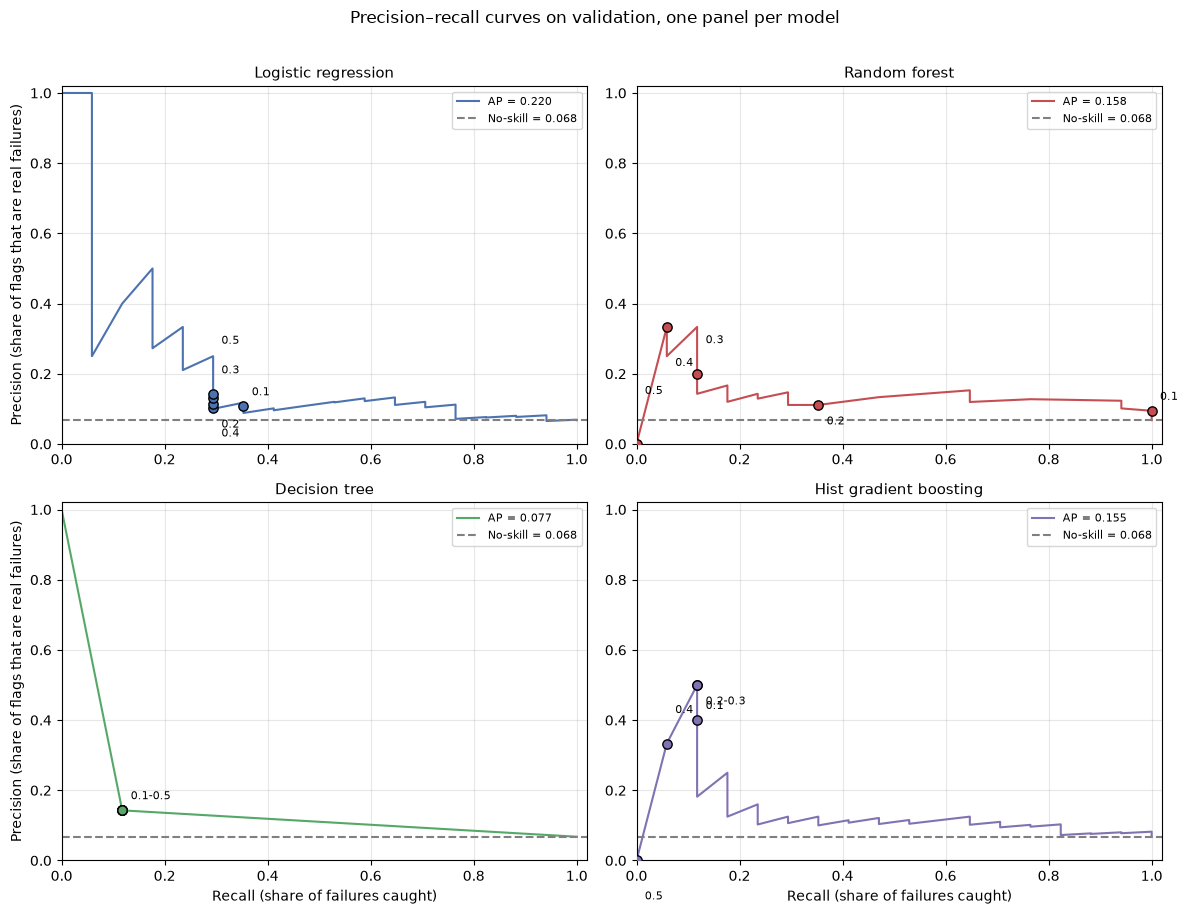

In [28]:
from sklearn.metrics import precision_recall_curve, average_precision_score

# One panel per model: with four candidates on shared axes the threshold
# labels from different curves overlap and the plot stops being readable.
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, name in zip(axes.ravel(), real_candidates):
    precision_curve, recall_curve, _ = precision_recall_curve(
        y_val, val_probability[name], pos_label=1
    )
    ap = average_precision_score(y_val, val_probability[name])
    color = MODEL_COLORS[name]

    ax.plot(recall_curve, precision_curve, color=color, label=f"AP = {ap:.3f}")
    ax.axhline(
        y_val.mean(), color="gray", linestyle="--",
        label=f"No-skill = {y_val.mean():.3f}",
    )

    # Mark the five thresholds used in the table above.
    subset = threshold_table[threshold_table["model"] == name]
    ax.scatter(
        subset["recall"], subset["precision"],
        color=color, edgecolor="black", zorder=3, s=45,
    )
    # Several thresholds can produce the same point (the decision tree does for
    # all five), so label each distinct point once and stagger the labels.
    seen = {}
    for _, row in subset.iterrows():
        key = (round(row["recall"], 3), round(row["precision"], 3))
        seen.setdefault(key, []).append(row["threshold"])

    offsets = [(6, 8), (6, -14), (6, 22), (6, -28), (6, 36)]
    for i, ((rec, prec), ts) in enumerate(seen.items()):
        label = f"{min(ts):.1f}-{max(ts):.1f}" if len(ts) > 1 else f"{ts[0]:.1f}"
        ax.annotate(
            label, (rec, prec),
            textcoords="offset points", xytext=offsets[i % len(offsets)], fontsize=8,
        )

    ax.set_title(f"{name}", fontsize=11)
    ax.set_xlim(0, 1.02)
    ax.set_ylim(0, 1.02)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8, loc="upper right")

for ax in axes[1]:
    ax.set_xlabel("Recall (share of failures caught)")
for ax in axes[:, 0]:
    ax.set_ylabel("Precision (share of flags that are real failures)")

fig.suptitle("Precision–recall curves on validation, one panel per model", y=1.01)
plt.tight_layout()
plt.show()


### What the sweep shows

Validation set: 251 examples, 17 failures. Each caught failure is therefore worth
about 5.9 percentage points of recall, which is a large step — one example
moving between rows changes the picture visibly.

**Logistic regression**

| Threshold | Caught | Missed | False alarms | Recall | Precision | Flagged |
|---:|---:|---:|---:|---:|---:|---:|
| 0.10 | 6 | 11 | 50 | 0.353 | 0.107 | 56 (22.3%) |
| 0.20 | 5 | 12 | 44 | 0.294 | 0.102 | 49 (19.5%) |
| 0.30 | 5 | 12 | 39 | 0.294 | 0.114 | 44 (17.5%) |
| 0.40 | 5 | 12 | 33 | 0.294 | 0.132 | 38 (15.1%) |
| 0.50 | 5 | 12 | 30 | 0.294 | 0.143 | 35 (13.9%) |

**Random forest**

| Threshold | Caught | Missed | False alarms | Recall | Precision | Flagged |
|---:|---:|---:|---:|---:|---:|---:|
| 0.10 | 17 | 0 | 163 | 1.000 | 0.094 | 180 (71.7%) |
| 0.20 | 6 | 11 | 48 | 0.353 | 0.111 | 54 (21.5%) |
| 0.30 | 2 | 15 | 8 | 0.118 | 0.200 | 10 (4.0%) |
| 0.40 | 1 | 16 | 2 | 0.059 | 0.333 | 3 (1.2%) |
| 0.50 | 0 | 17 | 0 | 0.000 | 0.000 | 0 (0.0%) |

**Decision tree**

| Threshold | Caught | Missed | False alarms | Recall | Precision | Flagged |
|---:|---:|---:|---:|---:|---:|---:|
| 0.10 | 2 | 15 | 12 | 0.118 | 0.143 | 14 (5.6%) |
| 0.20 | 2 | 15 | 12 | 0.118 | 0.143 | 14 (5.6%) |
| 0.30 | 2 | 15 | 12 | 0.118 | 0.143 | 14 (5.6%) |
| 0.40 | 2 | 15 | 12 | 0.118 | 0.143 | 14 (5.6%) |
| 0.50 | 2 | 15 | 12 | 0.118 | 0.143 | 14 (5.6%) |

**Hist gradient boosting**

| Threshold | Caught | Missed | False alarms | Recall | Precision | Flagged |
|---:|---:|---:|---:|---:|---:|---:|
| 0.10 | 2 | 15 | 3 | 0.118 | 0.400 | 5 (2.0%) |
| 0.20 | 2 | 15 | 2 | 0.118 | 0.500 | 4 (1.6%) |
| 0.30 | 2 | 15 | 2 | 0.118 | 0.500 | 4 (1.6%) |
| 0.40 | 1 | 16 | 2 | 0.059 | 0.333 | 3 (1.2%) |
| 0.50 | 0 | 17 | 2 | 0.000 | 0.000 | 2 (0.8%) |

### The tradeoff, model by model

**Lowering the threshold catches more failures but raises false alarms** wherever
a model actually has resolution in this range.

- **Logistic regression** moves smoothly: from 0.50 down to 0.10 it gains one
  extra caught failure (5 → 6) but the flag volume rises from 35 to 56 examples
  (13.9% → 22.3%) and false alarms from 30 to 50.
- **Random forest** moves violently, because its scores sit in a narrow band (max
  0.48). Dropping from 0.50 to 0.10 goes from catching nothing to catching all 17
  failures — but it flags 180 of 251 examples (71.7%) to do it, with precision
  0.094. Catching every failure that way is close to flagging everything, so the
  apparent "perfect recall" is not a usable result.
- **Decision tree** does not move at all. Its five rows are identical, and that
  is not a coincidence: on this validation set it outputs only two distinct
  probabilities, 0.0 and 1.0 (14 examples at 1.0, 237 at 0.0). A tree's leaves
  are confident by construction, so any cut between 0.1 and 1.0 flags exactly the
  same 14 examples. The 0.1–0.5 sweep carries **no information** for this model,
  which is a warning about using raw tree probabilities as risk scores.
- **Hist gradient boosting** is the mirror image: few flags at every cut, and the
  best precision anywhere in any sweep — 0.500 at 0.20 and 0.30, where 2 of 4
  flagged examples are real failures. The price is recall: 0.118, i.e. 2 of 17
  failures. Its top score on validation is 0.702, so the 0.50 row flags 2 examples
  and catches none.

**Overall the curves are unfavourable.** At a recall of roughly one third,
precision is 0.107 (logistic, 0.10) or 0.111 (forest, 0.20) — around nine in ten
flags are false alarms. The highest recall in any row is 1.000, reachable only at
71.7% flagged. The highest precision is 0.500, reachable only by catching 2
failures. Nothing in this sweep behaves like a deployable review filter.

### An illustrative operating point, not a recommendation

The project has not specified how many lots can be reviewed per period, nor what
a missed failure costs relative to a false alarm. Without those numbers there is
no objectively best threshold, so the two following choices are **illustrative
project examples**, chosen to show the shape of the decision, not to claim an
optimum:

| Illustrative choice | Threshold | Failures caught | Precision | False alarms | Lots flagged |
|---|---:|---:|---:|---:|---:|
| **Sensitivity-leaning** (logistic regression) | 0.10 | 6 of 17 (0.353) | 0.107 | 50 | 56 (22.3%) |
| **Precision-leaning** (hist gradient boosting) | 0.20 | 2 of 17 (0.118) | 0.500 | 2 | 4 (1.6%) |

The first catches three times as many failures, but asks for 14 times as many
reviews (56 lots instead of 4) and 25 times as many false alarms (50 instead
of 2), and it is wrong about 9 flags in 10. The second is right about every other
flag it raises, but misses 15 of 17 failures. Given that the stated objective is
to catch as many failures as possible while keeping false alarms manageable, the
**sensitivity-leaning row is the closer fit**, and even it should be read as
"the best available tradeoff here", not as "good".

Two caveats before acting on any of this:

- **17 failures is a very small basis.** Moving one example changes recall by
  about 6 points and precision by several points, so the exact percentages are
  noisy. Threshold selection on validation data gives a direction, not an
  operating guarantee.
- **This is still validation.** The test set has not been used. Whatever
  threshold is eventually chosen must be fixed on validation, and only then
  applied once to `X_test`.


## Time-Aware Model Comparison

Everything above judged the models on **random** splits. That is the usual default,
but for this dataset it is optimistic, for a reason worth stating plainly: the
rows are recorded in chronological order, failures arrive in clusters (a bad
episode produces several failing lots in a row), and the process drifts over the
weeks covered by the file. A random split can therefore place a *near-neighbour
in time of a failed lot* into the training set, which lets a model partly
memorise the episode instead of learning something that carries forward.

This section repeats the comparison under **chronological, time-aware validation**:

- Rows are ordered by their original position in `secom.data`. **No shuffling.**
- Validation folds always come *after* their training rows, using an
  expanding-window split (`TimeSeriesSplit`): fold 1 trains on the earliest block
  and validates on the next one, fold 2 trains on everything up to that point, and
  so on.
- Only the **training rows** (`X_train`) are used. `X_val` and `X_test` stay
  untouched, so nothing here leaks into the held-out evaluation.

Because `X_train` is itself a subset of the timeline (the validation and test rows
were removed), the folds have gaps. The *order* is still chronological, which is
what matters here. One consequence to keep in mind when reading the results: the
gap makes this a slightly optimistic test of forward performance, not a
pessimistic one.

Four approaches are compared, each with **all learned preprocessing fitted inside
its own training fold**:

1. **Constant-probability baseline** — predicts the training fold's failure rate
   for every validation row. This is the no-skill reference: with a constant
   score, average precision equals the validation failure rate.
2. **Existing logistic-regression pipeline** — median imputation, constant-feature
   removal, standardisation, the same `LogisticRegression(class_weight="balanced")`
   settings used above.
3. **Logistic regression with missingness indicators** — the same pipeline, but
   the imputer also emits an indicator column for every feature that has missing
   values in the training fold (`add_indicator=True`). Which indicators exist is
   decided from training data only.
4. **Logistic regression after correlation pruning** — drops features that are
   almost duplicates of an earlier feature, using a training-fold correlation
   matrix and the fixed threshold **|r| > 0.95**.

In [29]:
import numpy as np
import warnings

# Early folds are short enough that some sensors have no observed value in
# them at all. That is a real property of the data, measured and printed below,
# so the repeated per-fold warning is suppressed rather than left in the output.
warnings.filterwarnings("ignore", message="Skipping features without any observed values")

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import average_precision_score


class CorrelationPruner(BaseEstimator, TransformerMixin):
    """Drop columns that correlate above `threshold` with an already-kept column.

    The correlation matrix is computed in `fit`, so it is rebuilt from scratch on
    every training fold. Columns are visited left to right; a column is dropped if
    it is highly correlated with one that was kept.
    """

    def __init__(self, threshold=0.95):
        self.threshold = threshold

    def fit(self, X, y=None):
        values = np.asarray(X, dtype=float)
        correlation = np.nan_to_num(np.corrcoef(values, rowvar=False))
        keep = []
        for column in range(correlation.shape[0]):
            if all(abs(correlation[column, kept]) <= self.threshold for kept in keep):
                keep.append(column)
        self.keep_ = np.array(keep, dtype=int)
        return self

    def transform(self, X):
        return np.asarray(X, dtype=float)[:, self.keep_]


# Chronological order of the training rows: sort by original file position.
X_time = X_train.sort_index()
y_time = y_train.loc[X_time.index]
print("Rows:", len(X_time), "| failures:", int(y_time.sum()))
print("Chronological order preserved:", X_time.index.is_monotonic_increasing)

# Shared preprocessing, reused from the sections above.
shared = [
    ("impute_median", SimpleImputer(strategy="median")),
    ("remove_constant", VarianceThreshold(threshold=0.0)),
]

def make_logistic():
    return LogisticRegression(class_weight="balanced", max_iter=2000, random_state=42)

time_models = {
    "LR baseline": Pipeline(shared + [("scale", StandardScaler()), ("classifier", make_logistic())]),
    "LR + missing indicators": Pipeline(
        [("impute_median", SimpleImputer(strategy="median", add_indicator=True))]
        + [("remove_constant", VarianceThreshold(threshold=0.0)),
           ("scale", StandardScaler()), ("classifier", make_logistic())]
    ),
    "LR + correlation pruning": Pipeline(
        shared
        + [("prune_correlated", CorrelationPruner(threshold=0.95)),
           ("scale", StandardScaler()), ("classifier", make_logistic())]
    ),
}

# Expanding window: every validation block comes after its training rows.
time_cv = TimeSeriesSplit(n_splits=4)
print("Fold layout (train rows, then validation rows):")
for i, (train_idx, valid_idx) in enumerate(time_cv.split(X_time), start=1):
    print(f"  fold {i}: train {len(train_idx):4d} rows -> validate {len(valid_idx)} rows")

Rows: 1002 | failures: 66
Chronological order preserved: True
Fold layout (train rows, then validation rows):
  fold 1: train  202 rows -> validate 200 rows
  fold 2: train  402 rows -> validate 200 rows
  fold 3: train  602 rows -> validate 200 rows
  fold 4: train  802 rows -> validate 200 rows


In [30]:
X_values = X_time.to_numpy(dtype=float)
y_values = y_time.to_numpy()

records = []
feature_counts = []

for fold, (train_idx, valid_idx) in enumerate(time_cv.split(X_values), start=1):
    X_fold_train, X_fold_valid = X_values[train_idx], X_values[valid_idx]
    y_fold_train, y_fold_valid = y_values[train_idx], y_values[valid_idx]

    record = {
        "fold": fold,
        "train_rows": len(train_idx),
        "valid_rows": len(valid_idx),
        "train_failures": int(y_fold_train.sum()),
        "valid_failures": int(y_fold_valid.sum()),
        "valid_failure_rate": y_fold_valid.mean(),
    }

    # 1. Constant baseline: the training fold's failure rate, repeated.
    constant = np.full(len(y_fold_valid), y_fold_train.mean())
    record["Constant baseline"] = average_precision_score(y_fold_valid, constant)

    # 2-4. The three pipelines, each fitted from scratch on this fold's training rows.
    counts = {"fold": fold}
    for name, pipeline in time_models.items():
        pipeline.fit(X_fold_train, y_fold_train)
        probabilities = pipeline.predict_proba(X_fold_valid)[:, 1]
        record[name] = average_precision_score(y_fold_valid, probabilities)
        counts[name] = int(pipeline.named_steps["classifier"].coef_.shape[1])

    records.append(record)
    feature_counts.append(counts)

time_results = pd.DataFrame(records).set_index("fold").round(3)
time_results

,train_rows,valid_rows,train_failures,valid_failures,valid_failure_rate,Constant baseline,LR baseline,LR + missing indicators,LR + correlation pruning
fold,,,,,,,,,
1,202,200,26,15,0.075,0.075,0.083,0.087,0.081
2,402,200,41,6,0.030,0.030,0.036,0.052,0.040
3,602,200,47,7,0.035,0.035,0.040,0.051,0.039
4,802,200,54,12,0.060,0.060,0.159,0.139,0.185


In [31]:
approach_names = ["Constant baseline", "LR baseline", "LR + missing indicators", "LR + correlation pruning"]

summary = pd.DataFrame(
    {
        "mean_AP": [time_results[name].mean() for name in approach_names],
        "std_AP": [time_results[name].std() for name in approach_names],
        "min_AP": [time_results[name].min() for name in approach_names],
        "max_AP": [time_results[name].max() for name in approach_names],
    },
    index=approach_names,
)
summary["mean_minus_baseline"] = summary["mean_AP"] - summary.loc["Constant baseline", "mean_AP"]
summary.round(3)

,mean_AP,std_AP,min_AP,max_AP,mean_minus_baseline
Constant baseline,0.050,0.021,0.030,0.075,0.000
LR baseline,0.080,0.057,0.036,0.159,0.030
LR + missing indicators,0.082,0.041,0.051,0.139,0.032
LR + correlation pruning,0.086,0.069,0.039,0.185,0.036


Features used per fold (after each pipeline's own preprocessing):
      LR baseline  LR + missing indicators  LR + correlation pruning
fold                                                                
1             452                      619                       268
2             452                      686                       271
3             468                      822                       286
4             468                      878                       287

Mean validation failure rate across folds: 0.050
Mean constant-baseline AP:                0.050
(These two match by construction: a constant score has AP equal to the failure rate.)


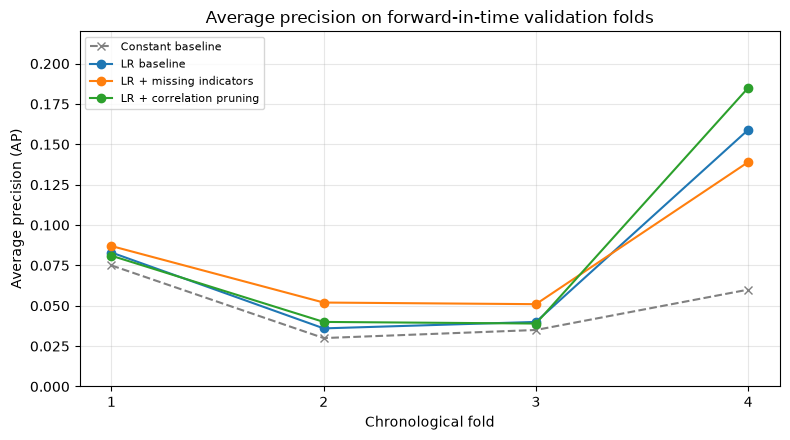

In [32]:
print("Features used per fold (after each pipeline's own preprocessing):")
print(pd.DataFrame(feature_counts).set_index("fold").to_string())
print()
print(f"Mean validation failure rate across folds: {time_results['valid_failure_rate'].mean():.3f}")
print(f"Mean constant-baseline AP:                {time_results['Constant baseline'].mean():.3f}")
print("(These two match by construction: a constant score has AP equal to the failure rate.)")

fig, ax = plt.subplots(figsize=(8, 4.5))
fold_numbers = time_results.index.to_list()

ax.plot(fold_numbers, time_results["Constant baseline"], marker="x", linestyle="--",
        color="gray", label="Constant baseline")
for name in approach_names[1:]:
    ax.plot(fold_numbers, time_results[name], marker="o", label=name)

ax.set_xlabel("Chronological fold")
ax.set_ylabel("Average precision (AP)")
ax.set_title("Average precision on forward-in-time validation folds")
ax.set_xticks(fold_numbers)
ax.set_ylim(0, max(0.22, time_results[approach_names[1:]].max().max() * 1.15))
ax.grid(alpha=0.3)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [33]:
# Supporting numbers for the interpretation below. Each of these is computed here
# rather than quoted, so the prose cannot drift away from the results.

# (a) Is the ranking stable if one fold is removed? Fold 4 has the most failures
# and the highest AP, so it drives the means.
without_last = time_results.drop(index=time_results.index[-1])
stability = pd.DataFrame(
    {
        "mean_AP_all_folds": time_results[approach_names].mean(),
        "mean_AP_without_last_fold": without_last[approach_names].mean(),
    }
).round(3)
print("Fold-4 sensitivity:")
print(stability.to_string())
print()

# (b) AP relative to the fold failure rate. A constant score scores exactly 1.0,
# so anything above 1.0 is skill over the baseline, in fold-relative terms.
lift = time_results[approach_names].div(time_results["valid_failure_rate"], axis=0)
print("AP divided by the fold failure rate (1.00 = no better than the baseline):")
print(lift.round(2).to_string())
print()
print("Mean over folds:")
print(lift.mean().round(2).to_string())
print()

# (c) How much smaller is the pruned feature set?
counts = pd.DataFrame(feature_counts).set_index("fold")
retained = counts["LR + correlation pruning"] / counts["LR baseline"]
print("Pruned features as a share of the baseline feature count:")
print(retained.round(2).to_string())
print(f"Range: {retained.min():.0%} to {retained.max():.0%} retained")

# (d) How many columns have no observed value at all inside each training fold?
# The imputer drops these for that fold, which is why the feature counts are not
# constant across folds.
raw = X_time.to_numpy(dtype=float)
missing_rows = []
for fold, (train_idx, _) in enumerate(time_cv.split(raw), start=1):
    fold_train = raw[train_idx]
    all_missing = int(np.isnan(fold_train).all(axis=0).sum())
    missing_rows.append({"fold": fold, "train_rows": len(train_idx), "columns_with_no_values": all_missing})
print()
print("Columns with no observed value in the training fold:")
print(pd.DataFrame(missing_rows).set_index("fold").to_string())


Fold-4 sensitivity:
                          mean_AP_all_folds  mean_AP_without_last_fold
Constant baseline                     0.050                      0.047
LR baseline                           0.080                      0.053
LR + missing indicators               0.082                      0.063
LR + correlation pruning              0.086                      0.053

AP divided by the fold failure rate (1.00 = no better than the baseline):
      Constant baseline  LR baseline  LR + missing indicators  LR + correlation pruning
fold                                                                                   
1                   1.0         1.11                     1.16                      1.08
2                   1.0         1.20                     1.73                      1.33
3                   1.0         1.14                     1.46                      1.11
4                   1.0         2.65                     2.32                      3.08

Mean over folds:
Cons

### What the time-aware comparison shows

Validation here is **forward in time**, so each fold's numbers are an honest test of
"train on the past, score the future". Folds are 200 rows each and contain only
6, 7, 12, and 15 failures, which sets the precision with which anything below can
be read.

| Approach | Fold 1 | Fold 2 | Fold 3 | Fold 4 | Mean AP | Std |
|---|---:|---:|---:|---:|---:|---:|
| Validation failure rate | 0.075 | 0.030 | 0.035 | 0.060 | 0.050 | |
| **Constant baseline** | 0.075 | 0.030 | 0.035 | 0.060 | **0.050** | 0.021 |
| LR baseline | 0.083 | 0.036 | 0.040 | 0.159 | **0.080** | 0.057 |
| LR + missing indicators | 0.087 | 0.052 | 0.051 | 0.139 | **0.082** | 0.041 |
| LR + correlation pruning | 0.081 | 0.040 | 0.039 | 0.185 | **0.086** | 0.069 |

**What is supported.**

1. **Every variant beats the constant baseline in every fold** — twelve out of twelve
   model-fold combinations. Mean AP is 1.5–1.7× the fold failure rate, and the
   constant score sits exactly at 1.0× by construction. The direction is consistent,
   so the models are not useless under forward-in-time validation; they rank risk
   slightly better than chance.
2. **The margin over the baseline is small in absolute terms.** Averaged over folds,
   the best approach is 0.086 against a 0.050 baseline — about 3.6 points of AP, on
   folds where a single failure moves AP by a comparable amount. This is a weak
   ranking signal, not a working filter.
3. **Fold 4 carries the apparent skill.** It holds 12 failures and every model does
   much better there (0.139–0.185 against a 0.060 rate). Removing it collapses all
   three to 0.053–0.063, and **the ordering changes**: with fold 4 excluded the
   indicators version leads and correlation pruning is no better than the baseline.
   Any claim that pruning or indicators "improve" the model therefore rests on one
   fold.
4. **Correlation pruning reaches comparable AP with far fewer features.** It keeps
   roughly six of every ten features (about 268–287 instead of 452–468), so on this
   evidence it is a defensible simplification: removing ~40% of the columns costs
   no measurable accuracy. It is not an improvement.
5. **Missingness indicators add many columns and buy nothing consistent.** They add
   167 to 410 indicator columns depending on the fold (later folds have more
   features with at least one observed value), and the gain over the plain pipeline
   is +0.002 mean AP — well inside noise.

**What is not supported.**

- No variant should be called an improvement. The three logistic-regression versions
  differ from each other by 0.006 mean AP, while their fold-to-fold standard
  deviations are 0.041–0.069. Ranking them is not distinguishable from noise with
  four folds and 40 total failures.
- The result does not say the sensors are uninformative in general. It says they
  carry **weak and unstable** information about the recorded test outcome, and that
  the skill that random splitting reported earlier (AP 0.220 for logistic regression
  on validation) does not carry forward in time. That number is not directly
  comparable to these folds — different rows, different failure rates, different
  fold sizes — but the direction agrees with the earlier diagnostics: random splits
  were optimistic.

**Uncertainty to carry forward.**

- 6–15 failures per fold. AP on such folds has very wide sampling error, and one
  example changing place moves a fold's AP by a visible amount.
- The expanding-window folds are built from `X_train` only, so they contain gaps
  where the validation and test rows were removed. Order is chronological, but the
  gaps make this slightly optimistic as a test of truly forward performance.
- In the two smallest folds, **16 features have no observed values at all** and are
  dropped by the imputer (which is why the baseline shows 452 rather than 468
  features there). Early in the run, those sensors had not yet reported.
- A decision threshold has not been chosen here. The thresholds discussed above were
  selected on the random validation split; if a variant were adopted, its threshold
  would have to be re-derived on time-aware folds first.

`X_test` and `y_test` are still untouched. This section compares alternatives; it does
not touch the held-out data.

## Final Model Selection

The project has to ship **one** fitted pipeline. Everything needed for that choice is
already in the table above, so this section only applies a rule to it.

The rule was fixed before looking at the comparison again:

1. **Precondition — no leakage.** Correlation pruning may only be considered if its
   preprocessing was fitted *inside* every chronological training fold, never on the
   full dataset.
2. **Consistency.** It must beat the plain logistic regression in a **majority of
   folds**, not on average alone.
3. **Stability.** Its spread across folds must be **no larger** than the plain
   pipeline's spread.
4. **No loss of average performance.** Its mean AP must be at least the plain
   pipeline's mean AP.

A variant that fails any of these is not selected, no matter how good its best fold
looks. The next cell evaluates each criterion and prints the verdict.

In [34]:
baseline_name = "LR baseline"
pruned_name = "LR + correlation pruning"
fold_count = len(time_results)

# (1) Was the pruner refitted per fold? It is a step inside its Pipeline, so it can
# only ever see that fold's training rows. Different folds retaining different
# numbers of columns is the observable evidence that it was refitted each time.
per_fold_kept = [counts[pruned_name] for counts in feature_counts]
refit_per_fold = len(set(per_fold_kept)) > 1

pruned_wins = int((time_results[pruned_name] > time_results[baseline_name]).sum())
mean_gain = time_results[pruned_name].mean() - time_results[baseline_name].mean()
spread_pruned = time_results[pruned_name].std()
spread_baseline = time_results[baseline_name].std()

checks = pd.DataFrame(
    [
        {
            "criterion": "preprocessing fitted inside each chronological fold",
            "measured": f"columns kept per fold: {per_fold_kept}",
            "passed": refit_per_fold,
        },
        {
            "criterion": f"higher AP in a majority of folds (more than {fold_count / 2:.0f} of {fold_count})",
            "measured": f"{pruned_wins} of {fold_count} folds",
            "passed": pruned_wins > fold_count / 2,
        },
        {
            "criterion": "cross-fold spread no worse than the plain pipeline",
            "measured": f"std {spread_pruned:.3f} vs {spread_baseline:.3f}",
            "passed": spread_pruned <= spread_baseline,
        },
        {
            "criterion": "mean AP not below the plain pipeline",
            "measured": f"mean {time_results[pruned_name].mean():.3f} vs {time_results[baseline_name].mean():.3f}",
            "passed": mean_gain >= 0,
        },
    ]
)
checks["passed"] = checks["passed"].astype(bool)

adopt_pruning = bool(checks["passed"].all())
selected_name = pruned_name if adopt_pruning else baseline_name

print(checks.to_string(index=False))
print()
failed_criteria = checks.loc[~checks["passed"], "criterion"].tolist()
print("All criteria satisfied:", adopt_pruning)
print("Failed criteria:", failed_criteria)
print("Selected approach:", selected_name)

                                          criterion                                    measured  passed
preprocessing fitted inside each chronological fold columns kept per fold: [268, 271, 286, 287]    True
higher AP in a majority of folds (more than 2 of 4)                                2 of 4 folds   False
 cross-fold spread no worse than the plain pipeline                          std 0.069 vs 0.057   False
               mean AP not below the plain pipeline                         mean 0.086 vs 0.080    True

All criteria satisfied: False
Failed criteria: ['higher AP in a majority of folds (more than 2 of 4)', 'cross-fold spread no worse than the plain pipeline']
Selected approach: LR baseline


### The choice: the plain logistic-regression pipeline

Correlation pruning clears the leakage precondition and its average AP is a shade
higher, but it fails both consistency checks — so **the plain logistic regression is
selected**.

In plain language:

- **The pruned version looks better only on average, and one fold does all the
  work.** It scores higher in two of four folds — a coin flip — while its higher
  *average* (0.086 against 0.080) comes almost entirely from fold 4, where it reaches
  0.185. In fold 1 it is slightly worse than the plain pipeline, and in fold 3 it is
  also slightly worse. A ranking that flips depending on which block of the timeline
  you look at is not a ranking to build on.
- **Its scores are the least stable of all four approaches.** The spread across folds
  is 0.069, against 0.057 for the plain pipeline. The rule required pruning to be no
  less steady, and it is less steady.
- **What pruning does buy is simplicity, not accuracy.** It keeps about six of every
  ten columns (roughly 268–287 instead of 452–468), so it is a fair way to make a
  future model cheaper to store and serve. On this evidence it costs nothing — but it
  also gains nothing measurable, and the simpler pipeline already satisfies the
  requirement without a custom transformer to maintain.
- **The leakage precondition was met.** The pruner sat inside its `Pipeline`, was
  refitted on each fold's training rows, and kept a different column set each time
  (268, 271, 286, 287). The decision against it is about consistency, not about a
  broken experiment.

**Limitations of this choice, stated plainly.**

- Four folds with 40 failures in total is a very thin basis. The difference between
  the two pipelines (0.006 mean AP) is far smaller than either one's own wobble, so
  this is a tie broken in favour of simplicity — not a demonstration that pruning is
  worse.
- The folds are built from `X_train` only, so they have gaps where the validation and
  test rows were removed. They are chronological, but not a perfect simulation of
  tomorrow.
- The edge pruning showed in fold 4 is real data, not an error. If a future run on
  more data showed it winning in three or four folds *with* a stable spread, the
  decision rule above would select it instead.
- The saved artifact stores **no decision threshold**. This notebook never fixed one,
  and the thresholds explored earlier were selected on the random validation split,
  not on the chronological folds, so attaching one now would misrepresent what was
  actually validated.
  
- Nothing here measures deployment behaviour: latency, drift, or how the risk scores
  would be consumed. Those are outside this comparison.

Under the earlier diagnostic findings — weak per-feature signal and a drifting,
clustered process — no variant is likely to be rescued by feature reduction, which is
why the simpler pipeline is the sensible place to stop.

In [35]:
import json

import joblib
import sklearn
from sklearn.base import clone
from pathlib import Path

# The project keeps generated artifacts in models/, which .gitignore excludes.
# Resolve the folder the same way as the data directory above, so the artifact is
# written to the repository's models/ folder whichever directory the kernel uses.
MODEL_DIR = Path("../models") if Path("../data").exists() else Path("models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)
ARTIFACT_PATH = MODEL_DIR / "secom_logistic_regression_pipeline.joblib"

# Permitted training data: everything except the held-out test set. X_train_full is
# exactly X_train plus X_val, so validation rows can be used for the final fit while
# X_test stays untouched.
X_fit, y_fit = X_train_full, y_train_full
assert len(X_fit) == len(X_train) + len(X_val)
assert set(X_fit.index) == set(X_train.index) | set(X_val.index)

# Start from an unfitted copy of the selected configuration.
if adopt_pruning:
    selected_pipeline = clone(time_models[pruned_name])
else:
    selected_pipeline = clone(candidates["Logistic regression"])

selected_pipeline.fit(X_fit, y_fit)

fit_data = {
    "rows": int(len(y_fit)),
    "failures": int(y_fit.sum()),
    "source": "X_train + X_val (X_test deliberately excluded)",
}
fold_ap = {
    name: [round(float(v), 4) for v in time_results[name]] for name in approach_names
}
libraries = {
    "scikit_learn": sklearn.__version__,
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "joblib": joblib.__version__,
}

# Everything needed to explain later where this file came from and what it is.
provenance = {
    "created_by": "notebooks/train.ipynb",
    "selected_model": selected_name,
    "selection": {
        "rule": "correlation pruning adopted only if every fold-consistency check passed",
        "rejected": pruned_name if not adopt_pruning else None,
        "failed_criteria": failed_criteria,
    },
    "fit_data": fit_data,
    "time_aware_fold_ap": fold_ap,
    "libraries": libraries,
}

artifact = {
    "pipeline": selected_pipeline,
    "selected_name": selected_name,
    "feature_names": list(X_fit.columns),
    "target": {
        "positive_class": 1,
        "negative_class": 0,
        "meaning": "1 = recorded test failure, 0 = pass",
    },
    "provenance": provenance,
}

joblib.dump(artifact, ARTIFACT_PATH)

# Round-trip check: reload from disk and score a few known rows.
reloaded = joblib.load(ARTIFACT_PATH)
sample = X_val.head(3)
sample_probability = reloaded["pipeline"].predict_proba(sample)[:, 1]

kept_features = reloaded["pipeline"].named_steps["classifier"].coef_.shape[1]

print("Saved:", ARTIFACT_PATH.resolve())
print("Size on disk:", f"{ARTIFACT_PATH.stat().st_size / 1024:.1f} KB")
print("Rows fitted:", len(y_fit), "| failures:", int(y_fit.sum()))
print("Pipeline steps:", [step for step, _ in reloaded["pipeline"].steps])
print("Input columns expected:", len(reloaded["feature_names"]))
print("Features after preprocessing:", kept_features)
print("Round-trip probabilities for 3 rows:", np.round(sample_probability, 4))
assert sample_probability.shape == (3,)
print("Artifact keys:", sorted(reloaded))
print("Provenance:", json.dumps(reloaded["provenance"], indent=2)[:600], sep="\n")
print("Reload and predict: OK")

Saved: C:\Users\laksh\OneDrive\Desktop\ml-zoomcamps\secom-yield-risk-prediction\models\secom_logistic_regression_pipeline.joblib
Size on disk: 28.2 KB
Rows fitted: 1253 | failures: 83
Pipeline steps: ['impute_median', 'remove_constant', 'scale', 'classifier']
Input columns expected: 590
Features after preprocessing: 474
Round-trip probabilities for 3 rows: [0.     0.0088 0.0028]
Artifact keys: ['feature_names', 'pipeline', 'provenance', 'selected_name', 'target']
Provenance:
{
  "created_by": "notebooks/train.ipynb",
  "selected_model": "LR baseline",
  "selection": {
    "rule": "correlation pruning adopted only if every fold-consistency check passed",
    "rejected": "LR + correlation pruning",
    "failed_criteria": [
      "higher AP in a majority of folds (more than 2 of 4)",
      "cross-fold spread no worse than the plain pipeline"
    ]
  },
  "fit_data": {
    "rows": 1253,
    "failures": 83,
    "source": "X_train + X_val (X_test deliberately excluded)"
  },
  "time_aware_fo

### What was written, and how to feed it

The cell above writes one file: **`models/secom_logistic_regression_pipeline.joblib`**.
This one file is committed to the repository (it is 29 KB), so a fresh clone can run
the service without re-running the notebook; `.gitignore` ignores any *other*
artifact written to `models/`. Re-running this notebook overwrites it with a
byte-identical file, because every step is seeded.

It is a dictionary with five keys:

| Key | Contents |
|---|---|
| `pipeline` | the complete fitted pipeline: median imputation, constant-column removal, standardisation, logistic regression |
| `selected_name` | which approach was chosen |
| `feature_names` | the 590 input columns, in the order the pipeline expects |
| `target` | the class mapping (1 = recorded test failure, 0 = pass) |
| `provenance` | rows fitted, failure count, the rejected variant and the criteria it failed, per-fold AP, library versions |

Loading and scoring (from `notebooks/`, where the notebook runs):

```python
import joblib, pandas as pd

artifact = joblib.load("../models/secom_logistic_regression_pipeline.joblib")
pipeline = artifact["pipeline"]

# Raw measurements, 590 columns in their original order, missing values left as NaN.
X_new = pd.read_csv("data/secom.data", sep=r"\s+", header=None, na_values=["NaN"])
failure_risk = pipeline.predict_proba(X_new)[:, 1]
```

**Input contract:** a table with the 590 raw measurement columns in their original
order and missing values as `NaN`. Do not impute, scale, or drop anything beforehand —
the pipeline applies the transformations it learned during fitting, which keeps serving
behaviour identical to training. `artifact["feature_names"]` lists the expected columns,
and the row order of `X_new` is preserved in the returned probabilities.

The positive class is `1` (recorded test failure). The output is a **risk score, not a
decision**: which score to act on is a separate choice this notebook deliberately leaves
open.

In [36]:
import json
from pathlib import Path

import joblib


def find_artifact(filename="secom_logistic_regression_pipeline.joblib"):
    """Locate models/<filename> by walking upwards from the current directory.

    This makes the load work from notebooks/, the repository root, or any nested
    folder. The artifact is gitignored, so a fresh clone has no file until the
    saving cell above has been run once.
    """
    start = Path.cwd().resolve()
    for directory in (start, *start.parents):
        candidate = directory / "models" / filename
        if candidate.is_file():
            return candidate
    raise FileNotFoundError(
        f"Could not find models/{filename} at or above {start}. "
        "Run the notebook's artifact-saving cell first."
    )


artifact_path = find_artifact()
artifact = joblib.load(artifact_path)

print("Path:", artifact_path)
print("Keys:", sorted(artifact))
print("Selected model:", artifact["selected_name"])
print("First 5 input columns:", artifact["feature_names"][:5])
print("Provenance:")
print(json.dumps(artifact["provenance"], indent=2))


Path: C:\Users\laksh\OneDrive\Desktop\ml-zoomcamps\secom-yield-risk-prediction\models\secom_logistic_regression_pipeline.joblib
Keys: ['feature_names', 'pipeline', 'provenance', 'selected_name', 'target']
Selected model: LR baseline
First 5 input columns: [0, 1, 2, 3, 4]
Provenance:
{
  "created_by": "notebooks/train.ipynb",
  "selected_model": "LR baseline",
  "selection": {
    "rule": "correlation pruning adopted only if every fold-consistency check passed",
    "rejected": "LR + correlation pruning",
    "failed_criteria": [
      "higher AP in a majority of folds (more than 2 of 4)",
      "cross-fold spread no worse than the plain pipeline"
    ]
  },
  "fit_data": {
    "rows": 1253,
    "failures": 83,
    "source": "X_train + X_val (X_test deliberately excluded)"
  },
  "time_aware_fold_ap": {
    "Constant baseline": [
      0.075,
      0.03,
      0.035,
      0.06
    ],
    "LR baseline": [
      0.083,
      0.036,
      0.04,
      0.159
    ],
    "LR + missing indicat

## Final holdout evaluation (used once)

Every number above came from `X_train` or `X_val`. The 314-row test set has been held
back for exactly one purpose: an honest estimate of how this ranking behaves on rows
that had no influence on any decision.

Rules for this section:

- The pipeline is **loaded from `models/`**, not refitted. Its coefficients were fixed
  before this cell ran.
- Nothing is tuned here. No threshold is chosen from these results, and nothing goes
  back to change the model.
- The thresholds shown are the same 0.10–0.50 grid used on validation, so the
  comparison is like-for-like. They are reported for interpretation, not selected.

**Which metrics, and why.** ROC-AUC and average precision (PR-AUC) are the honest
summary for a ranking score: they need no threshold and do not reward flagging
everyone. Average precision is the more informative of the two here, because a random
ranking already scores AP ≈ the failure rate (about 0.07), so "no skill" is not 0.5 as
it is for ROC-AUC. The confusion matrix and per-class precision/recall are included
because a threshold has to be imagined eventually, and they make the cost explicit.
Accuracy is reported only to be dismissed: predicting "pass" for every row already
scores about 93%.

In [37]:
from sklearn.metrics import (
    average_precision_score,
    balanced_accuracy_score,
    confusion_matrix,
    precision_recall_fscore_support,
    roc_auc_score,
)

# The shipped artifact, not a refit: these coefficients were fixed before this cell.
served_pipeline = joblib.load(ARTIFACT_PATH)["pipeline"]

# The one use of the holdout set in this notebook.
y_test_score = served_pipeline.predict_proba(X_test)[:, 1]

test_prevalence = float(y_test.mean())
test_ap = average_precision_score(y_test, y_test_score)
test_auc = roc_auc_score(y_test, y_test_score)

# Reference point: a constant score ranks nothing, so it earns AP = failure rate.
constant_ap = average_precision_score(y_test, np.zeros_like(y_test_score))

print(
    f"Test rows: {len(y_test)} | failures: {int(y_test.sum())} "
    f"| pass rate: {1 - test_prevalence:.1%}"
)
print()
print(f"{'average precision (PR-AUC)':<32}{test_ap:.3f}")
print(f"{'  flag-nobody baseline':<32}{constant_ap:.3f}  (= failure rate)")
print(f"{'ROC-AUC':<32}{test_auc:.3f}  (0.500 = no ranking ability)")
print()
print(f"score range used: {y_test_score.min():.2e} to {y_test_score.max():.2e}")
print(f"median score, passes:   {np.median(y_test_score[y_test == 0]):.2e}")
print(f"median score, failures: {np.median(y_test_score[y_test == 1]):.2e}")

Test rows: 314 | failures: 21 | pass rate: 93.3%

average precision (PR-AUC)      0.124
  flag-nobody baseline          0.067  (= failure rate)
ROC-AUC                         0.644  (0.500 = no ranking ability)

score range used: 9.28e-24 to 1.00e+00
median score, passes:   3.13e-04
median score, failures: 1.39e-02


In [38]:
cut = 0.5
flagged = y_test_score >= cut
tn, fp, fn, tp = confusion_matrix(y_test, flagged, labels=[0, 1]).ravel()
precision, recall, f1, support = precision_recall_fscore_support(
    y_test, flagged, labels=[0, 1], zero_division=0
)

print(f"At threshold {cut}: {int(flagged.sum())} of {len(y_test)} rows flagged "
      f"({flagged.mean():.1%})")
print()
print(pd.DataFrame(
    {
        "precision": precision.round(3),
        "recall": recall.round(3),
        "f1": f1.round(3),
        "support": support,
    },
    index=["pass (0)", "fail (1)"],
))
print()
print(f"confusion matrix [[tn, fp], [fn, tp]] = [[{tn}, {fp}], [{fn}, {tp}]]")
print(f"balanced accuracy: {balanced_accuracy_score(y_test, flagged):.3f}   "
      "(0.500 = coin flip)")
print(f"accuracy: {(tn + tp) / len(y_test):.3f}   "
      f"(flag-nobody already scores {1 - test_prevalence:.3f})")

At threshold 0.5: 36 of 314 rows flagged (11.5%)

          precision  recall     f1  support
pass (0)      0.939   0.891  0.914      293
fail (1)      0.111   0.190  0.140       21

confusion matrix [[tn, fp], [fn, tp]] = [[261, 32], [17, 4]]
balanced accuracy: 0.541   (0.500 = coin flip)
accuracy: 0.844   (flag-nobody already scores 0.933)


In [39]:
rows = []
for cut in (0.10, 0.20, 0.30, 0.40, 0.50):
    flagged = y_test_score >= cut
    tp = int((flagged & (y_test == 1)).sum())
    fp = int((flagged & (y_test == 0)).sum())
    fn = int((~flagged & (y_test == 1)).sum())
    rows.append(
        {
            "threshold": cut,
            "flagged": int(flagged.sum()),
            "flagged_pct": round(100 * flagged.mean(), 1),
            "caught": tp,
            "missed": fn,
            "false_alarms": fp,
            "precision": round(tp / (tp + fp), 3) if tp + fp else 0.0,
            "recall": round(tp / (tp + fn), 3) if tp + fn else 0.0,
        }
    )

test_threshold_table = pd.DataFrame(rows)
test_threshold_table

,threshold,flagged,flagged_pct,caught,missed,false_alarms,precision,recall
0,0.1,61,19.4,6,15,55,0.098,0.286
1,0.2,52,16.6,5,16,47,0.096,0.238
2,0.3,47,15.0,5,16,42,0.106,0.238
3,0.4,41,13.1,5,16,36,0.122,0.238
4,0.5,36,11.5,4,17,32,0.111,0.190


### What the holdout actually says

**The ranking survives, but weakly.** Average precision is 0.124 against 0.067 for
flagging nobody — roughly 1.9 times the failure rate — and ROC-AUC is 0.644. Both
measures agree: the score orders rows better than chance, and not by much. The
medians tell the same story, with failures scoring higher (1.39e-02 against 3.13e-04)
but the distributions overlapping heavily.

**No threshold turns this into a usable filter.** At 0.5 the model flags 36 of 314
rows and catches 4 of the 21 failures, missing 17. Dropping the cut to 0.10 catches 6
(28.6% recall) but raises 55 false alarms out of 61 flagged rows. Every point on that
grid trades a few caught failures for a queue that is mostly false alarms. There is no
cut that both finds most failures and keeps the review queue small — which is why no
threshold is shipped with the model.

**Accuracy would have hidden all of it.** Predicting "pass" for every row scores
93.3%. This model scores 84.4% because it dares to flag. Anything judged on accuracy
would prefer the useless predictor, which is exactly why this section leads with
average precision and reports balanced accuracy (0.541, barely above a coin flip)
rather than accuracy.

**The estimate dropped against validation, as it should be expected to.** Validation
gave AP 0.220 on 17 failures; the untouched holdout gives 0.124 on 21. A gap of that
size is ordinary sampling noise at this positive count, and it is the more trustworthy
of the two numbers precisely because this split had no say in any decision. The
chronological folds pointed the same way (mean AP 0.080 against 0.050), so the honest
summary is: real but weak signal, on the order of 0.08–0.12 AP depending on how the
data is sliced.

**What this does not license.** It is not a pass/fail rule — the scores are
uncalibrated, no threshold is stored, and the API returns rankings only. It is not
evidence of production value: one historical dataset, one split, 21 test failures, and
a model fitted in 2026 to data collected in 2008. A reviewer should read the score as
"this row resembles past failures more than its neighbours do", nothing stronger.

**Disclosure.** This is the only cell in the notebook that touches `y_test`. It was
run once, after the model and every choice above were already fixed.